# FTWP Chapter 3 Capstone
## Pricing and Hedging in an Incomplete Three-State Market

### Objective

Investigate how an incomplete market changes pricing and hedging.

For the same contingent claim, I will compare:

1. least-squares replication,
2. lower and upper no-arbitrage price bounds,
3. a benchmark martingale-measure price.

I will also examine state-by-state replication errors and construct
a claim with an interesting error pattern.

## Capstone Roadmap

### Part 1 — Define the claim

### Part 2 — Least-squares replication

### Part 3 — No-arbitrage price bounds

### Part 4 — Benchmark martingale-measure price

### Part 5 — Compare the pricing methods

### Part 6 — Visualize replication errors

### Part 7 — Design a surprising claim

### Part 8 — Financial interpretation and conclusions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=5, suppress=True)

In [2]:
states = ["Up", "Middle", "Down"]

# Risk-free bond
B0 = 10.0
B1 = np.array([11.0, 11.0, 11.0])

# Risky stock
S0 = 10.0
S1 = np.array([20.0, 10.0, 5.0])

# Market payoff matrix:
# rows = states, columns = traded assets
M = np.column_stack((B1, S1))

# Risk-free interest rate
i = B1[0] / B0 - 1.0

print("States:", states)
print("Bond payoff:", B1)
print("Stock payoff:", S1)
print("Payoff matrix M:")
print(M)
print("Risk-free rate:", i)
print("Shape of M:", M.shape)

States: ['Up', 'Middle', 'Down']
Bond payoff: [11. 11. 11.]
Stock payoff: [20. 10.  5.]
Payoff matrix M:
[[11. 20.]
 [11. 10.]
 [11.  5.]]
Risk-free rate: 0.10000000000000009
Shape of M: (3, 2)


## Part 1 — Define the Claim and Test Attainability

I use the up-state Arrow–Debreu claim

$$
C_1 = (1,0,0),
$$

which pays one unit in the Up state and zero in the Middle and Down states.

The first question is whether this claim is attainable using the two traded
assets. Exact attainability requires the existence of portfolio holdings
$\phi$ satisfying

$$
M\phi = C_1.
$$

Because the market has three future states but only two traded payoff vectors,
the attainable payoffs form at most a two-dimensional subspace of
$\mathbb{R}^3$. I therefore test formally whether this particular claim lies
inside that subspace.

In [3]:
C1 = np.array([1.0, 0.0, 0.0])

print("Claim payoff:", C1)
print("Claim shape:", C1.shape)

Claim payoff: [1. 0. 0.]
Claim shape: (3,)


### Attainability Test

A claim is exactly attainable if it lies in the span of the traded payoff
vectors. Equivalently, the linear system

$$
M\phi = C_1
$$

must have an exact solution.

I test this by comparing the rank of the market payoff matrix $M$ with the
rank of the augmented matrix $[M \mid C_1]$.

- If the ranks are equal, the claim lies in the span of the traded assets and is attainable.
- If the augmented matrix has higher rank, the claim introduces an additional independent payoff direction and is not attainable.

In [4]:
rank_M = np.linalg.matrix_rank(M)

augmented_matrix = np.column_stack((M, C1))
rank_augmented = np.linalg.matrix_rank(augmented_matrix)

print("Rank of market payoff matrix:", rank_M)
print("Rank of augmented matrix:", rank_augmented)
print("Exactly attainable:", rank_M == rank_augmented)

Rank of market payoff matrix: 2
Rank of augmented matrix: 3
Exactly attainable: False


### Interpretation

The market payoff matrix has rank 2, while the augmented matrix that includes
the claim has rank 3.

Therefore, adding $C_1$ introduces an independent payoff direction that cannot
be generated by any combination of the bond and stock. The system

$$
M\phi = C_1
$$

has no exact solution, so the claim is **unattainable**.

Financially, this is the key consequence of market incompleteness in this
example. Because the claim cannot be replicated exactly, there is no unique
replication-based price. The remaining sections therefore examine alternative
ways to hedge and price the claim.

## Part 2 — Least-Squares Replication

Because the claim is unattainable, exact replication is impossible. I therefore
replace the exact system

$$
M\phi = C_1
$$

with an approximation problem.

The least-squares portfolio chooses holdings $\hat{\phi}$ that minimize the
squared state-by-state replication error:

$$
\hat{\phi}
=
\arg\min_{\phi}
\|C_1 - M\phi\|_2^2.
$$

The resulting portfolio payoff $M\hat{\phi}$ is the attainable payoff vector
closest to the claim in the least-squares sense.

The residual

$$
e = C_1 - M\hat{\phi}
$$

measures the remaining state-by-state hedging error. A nonzero residual is the
part of the claim that cannot be hedged using the traded bond and stock.

In [5]:
phi_ls, _, _, _ = np.linalg.lstsq(M, C1, rcond=None)

ls_payoff = M @ phi_ls
ls_residual = C1 - ls_payoff

ls_residual_norm = np.linalg.norm(ls_residual)
ls_mse = np.mean(ls_residual ** 2)

ls_cost = B0 * phi_ls[0] + S0 * phi_ls[1]

print("Least-squares holdings:", phi_ls)
print("Least-squares payoff:", ls_payoff)
print("Residual:", ls_residual)
print("Residual norm:", ls_residual_norm)
print("Mean squared error:", ls_mse)
print("Cost of least-squares hedge:", ls_cost)

Least-squares holdings: [-0.04545  0.07143]
Least-squares payoff: [ 0.92857  0.21429 -0.14286]
Residual: [ 0.07143 -0.21429  0.14286]
Residual norm: 0.2672612419124244
Mean squared error: 0.023809523809523808
Cost of least-squares hedge: 0.25974025974025977


### Derivation and Interpretation of the Least-Squares Solution

The Python least-squares solver returns the portfolio

$$
\hat{\phi}
\approx
\begin{pmatrix}
-0.04545\\
0.07143
\end{pmatrix}.
$$

The purpose of this section is to derive these portfolio weights, identify
exactly what least squares is minimizing, and interpret the resulting hedge
financially.

---

#### 1. Market Payoffs and the Target Claim

The market payoff matrix is

$$
M
=
\begin{pmatrix}
11 & 20\\
11 & 10\\
11 & 5
\end{pmatrix}.
$$

Its columns are the future payoff vectors of the two traded assets:

$$
B_1
=
\begin{pmatrix}
11\\
11\\
11
\end{pmatrix},
\qquad
S_1
=
\begin{pmatrix}
20\\
10\\
5
\end{pmatrix}.
$$

A bond-stock portfolio is represented by

$$
\phi
=
\begin{pmatrix}
\phi_B\\
\phi_S
\end{pmatrix},
$$

where

- $\phi_B$ is the position in the bond;
- $\phi_S$ is the position in the stock.

Its future payoff is therefore

$$
M\phi
=
\begin{pmatrix}
11\phi_B+20\phi_S\\
11\phi_B+10\phi_S\\
11\phi_B+5\phi_S
\end{pmatrix}.
$$

The target claim is the up-state Arrow-Debreu claim

$$
C_1
=
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix},
$$

which pays one unit in the Up state and zero in the Middle and Down states.

---

#### 2. Why Least Squares Is Required

Part 1 established that

$$
\operatorname{rank}(M)=2,
\qquad
\operatorname{rank}([M\mid C_1])=3.
$$

Therefore,

$$
C_1\notin\operatorname{col}(M),
$$

so there is no portfolio $\phi$ satisfying

$$
M\phi=C_1.
$$

The claim is unattainable, and exact replication is impossible.

The problem therefore changes from finding an exact replicating portfolio to
finding the attainable payoff that is closest to $C_1$ under a specified error
criterion.

For this capstone, that criterion is least squares.

---

#### 3. The Least-Squares Replication Problem

The least-squares portfolio solves

$$
\boxed{
\hat{\phi}
=
\arg\min_{\phi\in\mathbb{R}^2}
\|C_1-M\phi\|_2^2
}.
$$

For a generic portfolio

$$
\phi
=
\begin{pmatrix}
\phi_B\\
\phi_S
\end{pmatrix},
$$

the residual vector is

$$
C_1-M\phi
=
\begin{pmatrix}
1-(11\phi_B+20\phi_S)\\
-(11\phi_B+10\phi_S)\\
-(11\phi_B+5\phi_S)
\end{pmatrix}.
$$

Hence the least-squares objective is

$$
\min_{\phi_B,\phi_S}
\left[
\left(1-11\phi_B-20\phi_S\right)^2
+
\left(11\phi_B+10\phi_S\right)^2
+
\left(11\phi_B+5\phi_S\right)^2
\right].
$$

Each term is the squared replication error in one future state.

Thus, least squares chooses the bond and stock positions that minimize the
**total squared replication error across the three states**.

---

#### 4. Deriving the Portfolio Weights

The minimizing portfolio satisfies the normal equations

$$
M^\top M\hat{\phi}
=
M^\top C_1.
$$

Since

$$
M^\top
=
\begin{pmatrix}
11 & 11 & 11\\
20 & 10 & 5
\end{pmatrix},
$$

we obtain

$$
M^\top M
=
\begin{pmatrix}
11 & 11 & 11\\
20 & 10 & 5
\end{pmatrix}
\begin{pmatrix}
11 & 20\\
11 & 10\\
11 & 5
\end{pmatrix}
=
\begin{pmatrix}
363 & 385\\
385 & 525
\end{pmatrix}.
$$

Also,

$$
M^\top C_1
=
\begin{pmatrix}
11 & 11 & 11\\
20 & 10 & 5
\end{pmatrix}
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix}
=
\begin{pmatrix}
11\\
20
\end{pmatrix}.
$$

Therefore,

$$
\begin{pmatrix}
363 & 385\\
385 & 525
\end{pmatrix}
\begin{pmatrix}
\hat{\phi}_B\\
\hat{\phi}_S
\end{pmatrix}
=
\begin{pmatrix}
11\\
20
\end{pmatrix},
$$

or equivalently,

$$
363\hat{\phi}_B+385\hat{\phi}_S=11,
$$

$$
385\hat{\phi}_B+525\hat{\phi}_S=20.
$$

Solving gives

$$
\hat{\phi}_B=-\frac{1}{22},
\qquad
\hat{\phi}_S=\frac{1}{14}.
$$

Hence,

$$
\boxed{
\hat{\phi}
=
\begin{pmatrix}
-\frac{1}{22}\\
\frac{1}{14}
\end{pmatrix}
\approx
\begin{pmatrix}
-0.04545\\
0.07143
\end{pmatrix}
}.
$$

Because the two columns of $M$ are linearly independent, $M$ has full column
rank. The least-squares solution is therefore unique.

Financially, the hedge consists of

- a short position of $\frac{1}{22}$ of the bond;
- a long position of $\frac{1}{14}$ of the stock.

These positions are not chosen arbitrarily. They are the unique bond-stock
weights that minimize the total squared replication error for this claim.

---

#### 5. Attainable Payoff Produced by the Hedge

Using the exact portfolio weights,

$$
M\hat{\phi}
=
\begin{pmatrix}
11 & 20\\
11 & 10\\
11 & 5
\end{pmatrix}
\begin{pmatrix}
-\frac{1}{22}\\
\frac{1}{14}
\end{pmatrix}.
$$

State by state,

$$
11\left(-\frac{1}{22}\right)
+
20\left(\frac{1}{14}\right)
=
-\frac{1}{2}
+
\frac{10}{7}
=
\frac{13}{14},
$$

$$
11\left(-\frac{1}{22}\right)
+
10\left(\frac{1}{14}\right)
=
-\frac{1}{2}
+
\frac{5}{7}
=
\frac{3}{14},
$$

and

$$
11\left(-\frac{1}{22}\right)
+
5\left(\frac{1}{14}\right)
=
-\frac{1}{2}
+
\frac{5}{14}
=
-\frac{1}{7}.
$$

Therefore,

$$
\boxed{
M\hat{\phi}
=
\begin{pmatrix}
\frac{13}{14}\\
\frac{3}{14}\\
-\frac{1}{7}
\end{pmatrix}
}
$$

or numerically,

$$
M\hat{\phi}
\approx
\begin{pmatrix}
0.92857\\
0.21429\\
-0.14286
\end{pmatrix}.
$$

This is the attainable payoff vector selected by the least-squares criterion.

It differs from

$$
C_1
=
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix},
$$

because the target claim is outside the attainable payoff space.

---

#### 6. Residual Risk and the Geometry of Least Squares

Define the residual by

$$
e=C_1-M\hat{\phi}.
$$

Substituting the exact payoff vectors gives

$$
e
=
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix}
-
\begin{pmatrix}
\frac{13}{14}\\
\frac{3}{14}\\
-\frac{1}{7}
\end{pmatrix}
=
\begin{pmatrix}
\frac{1}{14}\\
-\frac{3}{14}\\
\frac{1}{7}
\end{pmatrix}.
$$

Thus,

$$
\boxed{
e
=
\begin{pmatrix}
\frac{1}{14}\\
-\frac{3}{14}\\
\frac{1}{7}
\end{pmatrix}
\approx
\begin{pmatrix}
0.07143\\
-0.21429\\
0.14286
\end{pmatrix}
}.
$$

State by state:

- **Up:** the hedge falls short of the claim by
  $\frac{1}{14}\approx0.07143$;
- **Middle:** the hedge exceeds the claim by
  $\frac{3}{14}\approx0.21429$;
- **Down:** the hedge falls short of the claim by
  $\frac{1}{7}\approx0.14286$.

The nonzero residual is the payoff component that cannot be eliminated using
the traded bond and stock.

A defining property of the least-squares solution is

$$
M^\top e=0.
$$

Since

$$
e=C_1-M\hat{\phi},
$$

this is equivalent to

$$
M^\top(C_1-M\hat{\phi})=0,
$$

which expands to

$$
M^\top C_1-M^\top M\hat{\phi}=0.
$$

Rearranging recovers the normal equations:

$$
M^\top M\hat{\phi}=M^\top C_1.
$$

Geometrically, the columns of $M$ span the attainable payoff subspace.
The least-squares payoff $M\hat{\phi}$ is the orthogonal projection of
$C_1$ onto that subspace, and the residual $e$ is perpendicular to every
attainable payoff direction.

Therefore, no alternative combination of the same bond and stock can reduce
the squared replication error further.

---

#### 7. Measuring the Replication Error

The Euclidean norm of the residual is

$$
\|e\|_2
=
\sqrt{
\left(\frac{1}{14}\right)^2
+
\left(-\frac{3}{14}\right)^2
+
\left(\frac{1}{7}\right)^2
}.
$$

Therefore,

$$
\|e\|_2^2
=
\frac{1}{196}
+
\frac{9}{196}
+
\frac{4}{196}
=
\frac{14}{196}
=
\frac{1}{14}.
$$

Hence,

$$
\boxed{
\|e\|_2
=
\frac{1}{\sqrt{14}}
\approx0.26726
}.
$$

The residual norm measures the overall Euclidean magnitude of the replication
error across the three states.

The mean squared error used here averages the squared errors equally across
the three states:

$$
\mathrm{MSE}
=
\frac{1}{3}
\sum_{i=1}^{3} e_i^2.
$$

Equivalently,

$$
\mathrm{MSE}
=
\frac{1}{3}\|e\|_2^2.
$$

Since

$$
\|e\|_2^2=\frac{1}{14},
$$

we obtain

$$
\mathrm{MSE}
=
\frac{1}{3}\left(\frac{1}{14}\right)
=
\frac{1}{42}.
$$

Thus,

$$
\boxed{
\mathrm{MSE}
=
\frac{1}{42}
\approx0.02381
}.
$$

The two error measures answer slightly different questions:

- $\|e\|_2$ measures the total magnitude of the residual vector;
- $\mathrm{MSE}$ measures the average squared replication error per state.

---

#### 8. Cost of the Least-Squares Hedge

The current asset-price vector is

$$
M_0
=
\begin{pmatrix}
B_0\\
S_0
\end{pmatrix}
=
\begin{pmatrix}
10\\
10
\end{pmatrix}.
$$

The cost of establishing the least-squares portfolio today is

$$
C_0^{LS}
=
M_0^\top\hat{\phi}.
$$

Equivalently,

$$
C_0^{LS}
=
\hat{\phi}_B B_0
+
\hat{\phi}_S S_0.
$$

Substituting the exact holdings,

$$
C_0^{LS}
=
10\left(-\frac{1}{22}\right)
+
10\left(\frac{1}{14}\right).
$$

Therefore,

$$
C_0^{LS}
=
-\frac{5}{11}
+
\frac{5}{7}
=
-\frac{35}{77}
+
\frac{55}{77}
=
\frac{20}{77}.
$$

Hence,

$$
\boxed{
C_0^{LS}
=
\frac{20}{77}
\approx0.25974
}.
$$

Financially,

- the short bond position generates cash at time $0$;
- the long stock position requires cash at time $0$;
- their net difference is the cost of establishing the approximate hedge.

---

#### 9. Why This Is a Hedge Cost, Not a Unique Claim Price

The quantity

$$
C_0^{LS}
=
\frac{20}{77}
\approx0.25974
$$

is the cost of the portfolio selected by the least-squares hedging criterion.

It is **not** automatically the unique arbitrage-free price of the contingent
claim.

In a complete market, exact replication would give

$$
M\phi=C_1,
$$

and the cost of that replicating portfolio would force the claim price through
the no-arbitrage principle.

Here, however,

$$
C_1\notin\operatorname{col}(M).
$$

There is no exact replicating portfolio, so that uniqueness argument is not
available.

Least squares instead selects one particular attainable approximation,

$$
M\hat{\phi},
$$

by minimizing a chosen error criterion. Its cost,

$$
C_0^{LS},
$$

is therefore an economically meaningful **hedge cost**, but it is not a price
uniquely imposed by no arbitrage.

Different admissible pricing rules can assign different values to the same
unattainable claim.

This leads to the next question:

> If exact replication cannot determine a unique price, what range of claim
> prices remains consistent with the absence of arbitrage?

That question leads to the martingale-measure price bounds in the incomplete
market.

## Part 3 — Martingale Measures and No-Arbitrage Price Bounds

The least-squares calculation produced an approximate hedge and its cost.
It did not determine a unique arbitrage-free price for the unattainable
claim.

To examine the possible claim prices, consider the martingale measures
consistent with the traded bond and stock.

The state ordering is

$$
(\text{Up},\text{Middle},\text{Down}).
$$

All three states are assumed to have positive physical probability.
Trading is frictionless, and long and short positions are permitted.

### Deriving the Martingale-Measure Family

Write

$$
Q=(q_u,q_m,q_d),
\qquad
q_u+q_m+q_d=1.
$$

The stock martingale condition is

$$
E^Q[S_1]=S_0(1+i).
$$

With

$$
S_0=10,
\qquad
i=0.10,
\qquad
S_1=(20,10,5),
$$

this becomes

$$
20q_u+10q_m+5q_d=11.
$$

Substitute

$$
q_d=1-q_u-q_m.
$$

Then

$$
20q_u+10q_m+5(1-q_u-q_m)=11,
$$

which simplifies to

$$
15q_u+5q_m=6.
$$

Therefore,

$$
q_m=\frac65-3q_u,
$$

and

$$
q_d=1-q_u-q_m=2q_u-\frac15.
$$

Writing $q=q_u$, the family is

$$
\boxed{
Q(q)=
\left(
q,\;
\frac65-3q,\;
2q-\frac15
\right).
}
$$

The bond condition is satisfied because its payoff is constant at 11,
its current price is 10, and the probabilities sum to one.

### Nonnegative Measures and Limiting Bounds

Nonnegativity requires

$$
2q-\frac15\geq0
\qquad\text{and}\qquad
\frac65-3q\geq0.
$$

Thus the closed family of nonnegative martingale probability measures
is obtained for

$$
\frac1{10}\leq q\leq\frac25.
$$

Its endpoint measures are

$$
Q_{\mathrm{lower}}=
\left(\frac1{10},\frac9{10},0\right)
$$

and

$$
Q_{\mathrm{upper}}=
\left(\frac25,0,\frac35\right).
$$

Both price the existing bond and stock consistently, but each assigns
zero probability to a physically possible state.

They are useful for calculating limiting price bounds. They are not
equivalent to the physical probability measure.

### Equivalent Martingale Measures

An equivalent martingale measure must preserve which states are possible.
Because all three states are physically possible here, its probabilities
must satisfy

$$
q_u>0,\qquad q_m>0,\qquad q_d>0.
$$

For this family, strict positivity gives

$$
\boxed{
\frac1{10}<q<\frac25.
}
$$

There are infinitely many such measures, reflecting the incompleteness
of the market.

### Pricing the Up-State Claim

For

$$
C_1=(1,0,0),
$$

the expected payoff under $Q(q)$ is

$$
E^{Q(q)}[C_1]=q.
$$

Its discounted value is therefore

$$
C_0(q)
=
\frac{1}{1+i}E^{Q(q)}[C_1]
=
\frac{10}{11}q.
$$

Using the strictly positive martingale measures gives the arbitrage-free
prices for the market in which this claim is also traded:

$$
\boxed{
\frac1{11}<C_0<\frac4{11}.
}
$$

The limiting lower and upper bounds are

$$
\underline C_0=\frac1{11},
\qquad
\overline C_0=\frac4{11}.
$$

These are the infimum and supremum of the arbitrage-free price set.
Neither endpoint is itself an arbitrage-free trading price for this
claim under the stated assumptions.

The next code cell evaluates the endpoint measures to calculate the
bounds. Evaluating those endpoints does not mean they are included in
the admissible claim-price interval.

In [6]:
# Closed range of nonnegative martingale measures.
# Equivalent measures require q_min < q < q_max.
q_min = 1.0 / 10.0
q_max = 2.0 / 5.0


def martingale_measure(q):
    """Construct the probability vector for this three-state market."""
    q_u = q
    q_m = 6.0 / 5.0 - 3.0 * q
    q_d = 2.0 * q - 1.0 / 5.0
    return np.array([q_u, q_m, q_d])


Q_lower = martingale_measure(q_min)
Q_upper = martingale_measure(q_max)

# Check stock expectations under the limiting measures.
stock_expectation_lower = float(Q_lower @ S1)
stock_expectation_upper = float(Q_upper @ S1)

# Limiting claim-price bounds, not admissible endpoint prices.
lower_bound = float((Q_lower @ C1) / (1.0 + i))
upper_bound = float((Q_upper @ C1) / (1.0 + i))

print("Lower limiting martingale measure:", Q_lower)
print("Upper limiting martingale measure:", Q_upper)
print()
print("E^Q_lower[S1]:", stock_expectation_lower)
print("E^Q_upper[S1]:", stock_expectation_upper)
print("Required stock value S0(1+i):", S0 * (1.0 + i))
print()
print("Lower limiting price bound:", lower_bound)
print("Upper limiting price bound:", upper_bound)
print("Arbitrage-free prices lie strictly between these bounds.")

# -------------------------------------------------
# Endpoint arbitrage verification
# -------------------------------------------------

# Columns: bond, stock, claim.
# Rows: Up, Middle, Down.
endpoint_payoff_matrix = np.column_stack((B1, S1, C1))

# At the lower price: buy the claim and hedge with bond and stock.
lower_trade_holdings = np.array([
    1.0 / 11.0,
    -1.0 / 10.0,
    1.0,
])

lower_trade_cost = float(
    np.array([B0, S0, lower_bound]) @ lower_trade_holdings
)
lower_trade_payoff = endpoint_payoff_matrix @ lower_trade_holdings

# At the upper price: short the claim and hedge with bond and stock.
upper_trade_holdings = np.array([
    -1.0 / 33.0,
    1.0 / 15.0,
    -1.0,
])

upper_trade_cost = float(
    np.array([B0, S0, upper_bound]) @ upper_trade_holdings
)
upper_trade_payoff = endpoint_payoff_matrix @ upper_trade_holdings

print()
print("Holdings order: bond, stock, claim")
print("Payoff state order:", states)
print()
print("Lower-endpoint trade holdings:", lower_trade_holdings)
print(f"Lower-endpoint initial cost: {lower_trade_cost:.12f}")
print("Lower-endpoint terminal payoff:", lower_trade_payoff)
print()
print("Upper-endpoint trade holdings:", upper_trade_holdings)
print(f"Upper-endpoint initial cost: {upper_trade_cost:.12f}")
print("Upper-endpoint terminal payoff:", upper_trade_payoff)

# Allow only tiny floating-point discrepancies around zero.
endpoint_tol = 1e-12

endpoint_checks = {
    "lower_zero_initial_cost": np.isclose(
        lower_trade_cost, 0.0, atol=endpoint_tol, rtol=0.0
    ),
    "lower_nonnegative_payoffs": np.all(
        lower_trade_payoff >= -endpoint_tol
    ),
    "lower_positive_payoff_possible": np.any(
        lower_trade_payoff > endpoint_tol
    ),
    "lower_payoff_matches_derivation": np.allclose(
        lower_trade_payoff,
        np.array([0.0, 0.0, 0.5]),
        atol=endpoint_tol,
        rtol=0.0,
    ),
    "upper_zero_initial_cost": np.isclose(
        upper_trade_cost, 0.0, atol=endpoint_tol, rtol=0.0
    ),
    "upper_nonnegative_payoffs": np.all(
        upper_trade_payoff >= -endpoint_tol
    ),
    "upper_positive_payoff_possible": np.any(
        upper_trade_payoff > endpoint_tol
    ),
    "upper_payoff_matches_derivation": np.allclose(
        upper_trade_payoff,
        np.array([0.0, 1.0 / 3.0, 0.0]),
        atol=endpoint_tol,
        rtol=0.0,
    ),
}

print()
for name, passed in endpoint_checks.items():
    print(f"{name}: {bool(passed)}")

failed_endpoint_checks = [
    name for name, passed in endpoint_checks.items()
    if not passed
]

assert not failed_endpoint_checks, (
    f"Endpoint checks failed: {failed_endpoint_checks}"
)

print()
print("All 8 endpoint-arbitrage checks passed.")

Lower limiting martingale measure: [0.1 0.9 0. ]
Upper limiting martingale measure: [ 0.4 -0.   0.6]

E^Q_lower[S1]: 11.0
E^Q_upper[S1]: 10.999999999999998
Required stock value S0(1+i): 11.0

Lower limiting price bound: 0.09090909090909091
Upper limiting price bound: 0.36363636363636365
Arbitrage-free prices lie strictly between these bounds.

Holdings order: bond, stock, claim
Payoff state order: ['Up', 'Middle', 'Down']

Lower-endpoint trade holdings: [ 0.09091 -0.1      1.     ]
Lower-endpoint initial cost: 0.000000000000
Lower-endpoint terminal payoff: [0.  0.  0.5]

Upper-endpoint trade holdings: [-0.0303   0.06667 -1.     ]
Upper-endpoint initial cost: -0.000000000000
Upper-endpoint terminal payoff: [-0.       0.33333 -0.     ]

lower_zero_initial_cost: True
lower_nonnegative_payoffs: True
lower_positive_payoff_possible: True
lower_payoff_matches_derivation: True
upper_zero_initial_cost: True
upper_nonnegative_payoffs: True
upper_positive_payoff_possible: True
upper_payoff_matche

### Derivation and Interpretation of the Martingale Price Bounds

The calculation gives two endpoint measures:

$$
Q_{\min}=(0.1,\;0.9,\;0),
\qquad
Q_{\max}=(0.4,\;0,\;0.6).
$$

They belong to the family

$$
Q(q)=
\left(
q,\;
\frac65-3q,\;
2q-\frac15
\right).
$$

Nonnegative probabilities require

$$
\frac1{10}\leq q\leq\frac25.
$$

However, the endpoints assign zero probability to a physically possible
state. They are therefore limiting martingale measures, not equivalent
martingale measures under this notebook's assumption that all three
states are possible.

#### 1. Checking the Endpoint Measures

Both endpoint measures have nonnegative probabilities summing to one.

They also satisfy the stock pricing restriction:

$$
E^{Q_{\min}}[S_1]
=
0.1(20)+0.9(10)+0(5)
=
11,
$$

and

$$
E^{Q_{\max}}[S_1]
=
0.4(20)+0(10)+0.6(5)
=
11.
$$

This matches

$$
S_0(1+i)=10(1.10)=11.
$$

The bond restriction also holds because its payoff is 11 in every
state and its current price is 10.

Tiny discrepancies in the displayed numerical results are
floating-point roundoff.

#### 2. Calculating the Limiting Claim-Price Bounds

The claim is

$$
C_1=(1,0,0).
$$

Under $Q(q)$, its expected payoff is $q$, so its discounted value is

$$
C_0(q)
=
\frac{q}{1+i}
=
\frac{10}{11}q.
$$

Evaluating the endpoint measures gives

$$
\underline C_0
=
\frac{10}{11}\left(\frac1{10}\right)
=
\boxed{\frac1{11}},
$$

and

$$
\overline C_0
=
\frac{10}{11}\left(\frac25\right)
=
\boxed{\frac4{11}}.
$$

Numerically, these bounds are approximately 0.09091 and 0.36364.

These calculations identify the infimum and supremum of the
arbitrage-free price set. They do not establish that the endpoint
prices themselves are admissible.

#### 3. Why the Lower Endpoint Allows Arbitrage

Suppose the claim could be traded at

$$
C_0=\frac1{11}.
$$

Consider holdings in the order

$$
(\text{bond},\text{stock},\text{claim}):
\qquad
\left(\frac1{11},-\frac1{10},1\right).
$$

This means buying the claim and a fraction of the bond while shorting
a fraction of the stock.

The initial cost is

$$
10\left(\frac1{11}\right)
+
10\left(-\frac1{10}\right)
+
\frac1{11}
=
0.
$$

Using

$$
B_1=(11,11,11),
\qquad
S_1=(20,10,5),
\qquad
C_1=(1,0,0),
$$

the terminal payoff is

$$
\frac1{11}B_1-\frac1{10}S_1+C_1
=
\boxed{\left(0,0,\frac12\right)}.
$$

This trade costs nothing, cannot lose in any state, and pays a positive
amount in the possible Down state. Therefore the lower endpoint is
not an arbitrage-free trading price.

#### 4. Why the Upper Endpoint Allows Arbitrage

Suppose instead that the claim could be traded at

$$
C_0=\frac4{11}.
$$

Take holdings

$$
(\text{bond},\text{stock},\text{claim}):
\qquad
\left(-\frac1{33},\frac1{15},-1\right).
$$

The initial cost is

$$
10\left(-\frac1{33}\right)
+
10\left(\frac1{15}\right)
-
\frac4{11}
=
0.
$$

The terminal payoff is

$$
-\frac1{33}B_1+\frac1{15}S_1-C_1
=
\boxed{\left(0,\frac13,0\right)}.
$$

This also costs nothing and has a nonnegative payoff in every state,
with a positive payoff in the possible Middle state. Therefore the
upper endpoint is not an arbitrage-free trading price either.

These examples assume frictionless trading and permission to take
the stated long and short positions.

#### 5. The Arbitrage-Free Price Set

Strictly positive martingale probabilities require

$$
\frac1{10}<q<\frac25.
$$

Consequently, the arbitrage-free prices for this claim are

$$
\boxed{
\frac1{11}<C_0<\frac4{11}.
}
$$

Every price strictly inside this interval corresponds to a strictly
positive martingale measure that prices the bond, stock, and claim
consistently.

The closed interval

$$
\left[\frac1{11},\frac4{11}\right]
$$

records the limiting bounds. The open interval

$$
\left(\frac1{11},\frac4{11}\right)
$$

is the admissible trading-price set for this claim.

This is not a statistical confidence interval. It describes the prices
consistent with no arbitrage under the stated market assumptions.

#### 6. Comparison With the Least-Squares Hedge Cost

The least-squares hedge cost from Part 2 is

$$
C_0^{LS}=\frac{20}{77}\approx0.25974.
$$

It lies strictly between the bounds:

$$
\frac1{11}
<
\frac{20}{77}
<
\frac4{11}.
$$

Thus this particular hedge cost is also an admissible claim price.
But least-squares fitting does not make it the uniquely correct price.

The calculations answer different questions:

- least squares chooses a traded-asset payoff that minimizes squared
  replication error;
- no-arbitrage pricing identifies the range of admissible prices for
  the original, unattainable claim.

The next section selects an interior martingale measure as an explicit
benchmark. That choice supplies one comparison price, not a price
uniquely determined by no arbitrage.

## Part 4 — Benchmark Martingale-Measure Price

Part 3 established that the incomplete market admits an entire family of
equivalent martingale measures,

$$
Q(q)
=
\left(
q,\;
\frac{6}{5}-3q,\;
2q-\frac{1}{5}
\right),
\qquad
\frac{1}{10}
<
q
<
\frac{2}{5}.
$$

No-arbitrage therefore determines a price interval for the unattainable claim,
not one unique price.

To obtain a single comparison value, I now choose one equivalent martingale
measure as a **benchmark**.

I use

$$
q=\frac{3}{10},
$$

which is an interior point of the admissible interval.

Substituting into the martingale-measure family gives

$$
q_u
=
\frac{3}{10},
$$

$$
q_m
=
\frac{6}{5}
-
3\left(\frac{3}{10}\right)
=
\frac{3}{10},
$$

and

$$
q_d
=
2\left(\frac{3}{10}\right)
-
\frac{1}{5}
=
\frac{4}{10}.
$$

Therefore,

$$
\boxed{
Q_{\mathrm{bench}}
=
\left(
\frac{3}{10},
\frac{3}{10},
\frac{4}{10}
\right)
}.
$$

Before using this measure to price the claim, I verify that

1. its probabilities are strictly positive;
2. they sum to one;
3. it correctly prices the traded stock through the martingale condition.

The benchmark price of the claim is then

$$
C_0^{\mathrm{bench}}
=
\frac{1}{1+i}
E^{Q_{\mathrm{bench}}}[C_1].
$$

Because

$$
C_1=(1,0,0),
$$

only the benchmark probability assigned to the Up state contributes to the
expected claim payoff.

In [7]:
q_benchmark = 3.0 / 10.0

Q_benchmark = martingale_measure(q_benchmark)

benchmark_probability_sum = np.sum(Q_benchmark)
benchmark_positive = np.all(Q_benchmark > 0.0)

benchmark_stock_expectation = np.dot(Q_benchmark, S1)

benchmark_claim_expectation = np.dot(Q_benchmark, C1)
benchmark_price = benchmark_claim_expectation / (1.0 + i)

print("Benchmark martingale measure:", Q_benchmark)
print("Probability sum:", benchmark_probability_sum)
print("All probabilities strictly positive:", benchmark_positive)
print()
print("E^Q_benchmark[S1]:", benchmark_stock_expectation)
print("Required stock value S0(1+i):", S0 * (1.0 + i))
print()
print("E^Q_benchmark[C1]:", benchmark_claim_expectation)
print("Benchmark claim price:", benchmark_price)

Benchmark martingale measure: [0.3 0.3 0.4]
Probability sum: 1.0
All probabilities strictly positive: True

E^Q_benchmark[S1]: 11.0
Required stock value S0(1+i): 11.0

E^Q_benchmark[C1]: 0.3
Benchmark claim price: 0.2727272727272727


### Derivation and Interpretation of the Benchmark Martingale Price

The Python calculation gives the benchmark martingale measure

$$
Q_{\mathrm{bench}}
=
(0.3,\;0.3,\;0.4).
$$

In exact form,

$$
\boxed{
Q_{\mathrm{bench}}
=
\left(
\frac{3}{10},
\frac{3}{10},
\frac{2}{5}
\right)
}.
$$

The purpose of this section is to verify that the selected measure is
admissible, confirm that it correctly prices the traded stock, and derive the
corresponding benchmark value of the contingent claim.

---

#### 1. Why This Measure Is Used as a Benchmark

Part 3 established the family of equivalent martingale measures

$$
Q(q)
=
\left(
q,\;
\frac{6}{5}-3q,\;
2q-\frac{1}{5}
\right),
\qquad
\frac{1}{10}
<
q
<
\frac{2}{5}.
$$

For the benchmark calculation, choose

$$
q=\frac{3}{10}.
$$

This is an interior point of the admissible interval because

$$
\frac{1}{10}
<
\frac{3}{10}
<
\frac{2}{5}.
$$

Substituting into the martingale-measure family gives

$$
q_u
=
\frac{3}{10},
$$

$$
q_m
=
\frac{6}{5}
-
3\left(\frac{3}{10}\right)
=
\frac{3}{10},
$$

and

$$
q_d
=
2\left(\frac{3}{10}\right)
-
\frac{1}{5}
=
\frac{2}{5}.
$$

Therefore,

$$
\boxed{
Q_{\mathrm{bench}}
=
\left(
\frac{3}{10},
\frac{3}{10},
\frac{2}{5}
\right)
}.
$$

This is an interior member of the admissible martingale-measure family rather
than one of the endpoint measures that generated the lower and upper
no-arbitrage price bounds.

---

#### 2. Verifying the Probability Measure

A valid probability measure must have nonnegative components whose sum is one.
Here, equivalence also requires strictly positive probabilities, because all
three states have positive physical probability.

Here,

$$
\frac{3}{10}>0,
\qquad
\frac{3}{10}>0,
\qquad
\frac{2}{5}>0,
$$

and

$$
\frac{3}{10}
+
\frac{3}{10}
+
\frac{2}{5}
=
1.
$$

Thus,

$$
\boxed{
\sum_{\omega}
Q_{\mathrm{bench}}(\omega)
=
1
}.
$$

The Python calculation confirms that all three probabilities are strictly
positive. Together with normalization and the pricing restrictions checked
below, this verifies that the benchmark is an equivalent martingale measure.

---

#### 3. Verifying the Stock Martingale Condition

A probability measure is not a valid martingale measure merely because its
components sum to one. It must also reproduce the observed price of the traded
stock through

$$
E^Q[S_1]
=
S_0(1+i).
$$

The stock payoff vector is

$$
S_1
=
\begin{pmatrix}
20\\
10\\
5
\end{pmatrix}.
$$

Under the benchmark measure,

$$
E^{Q_{\mathrm{bench}}}[S_1]
=
\frac{3}{10}(20)
+
\frac{3}{10}(10)
+
\frac{2}{5}(5).
$$

Therefore,

$$
E^{Q_{\mathrm{bench}}}[S_1]
=
6+3+2
=
11.
$$

The current stock price and risk-free rate imply

$$
S_0(1+i)
=
10(1.10)
=
11.
$$

Hence,

$$
\boxed{
E^{Q_{\mathrm{bench}}}[S_1]
=
S_0(1+i)
=
11
}.
$$

The benchmark measure therefore satisfies the stock martingale condition and
is consistent with the observed prices of the traded assets.

---

#### 4. Expected Payoff of the Claim

The contingent claim is

$$
C_1
=
(1,\;0,\;0).
$$

Its expected payoff under the benchmark measure is

$$
E^{Q_{\mathrm{bench}}}[C_1]
=
\frac{3}{10}(1)
+
\frac{3}{10}(0)
+
\frac{2}{5}(0).
$$

Therefore,

$$
\boxed{
E^{Q_{\mathrm{bench}}}[C_1]
=
\frac{3}{10}
}.
$$

Because the claim pays only in the Up state, its expectation under a
martingale measure is simply the probability that the measure assigns to that
state.

---

#### 5. Discounting the Expected Payoff

The one-period gross risk-free return is

$$
1+i
=
1.10
=
\frac{11}{10}.
$$

Therefore, the discount factor is

$$
\frac{1}{1+i}
=
\frac{10}{11}.
$$

The benchmark martingale price is

$$
C_0^{\mathrm{bench}}
=
\frac{1}{1+i}
E^{Q_{\mathrm{bench}}}[C_1].
$$

Substituting the benchmark expectation,

$$
C_0^{\mathrm{bench}}
=
\frac{10}{11}
\left(
\frac{3}{10}
\right).
$$

Hence,

$$
\boxed{
C_0^{\mathrm{bench}}
=
\frac{3}{11}
\approx
0.27273
}.
$$

This agrees with the numerical value returned by Python.

---

#### 6. Position Within the No-Arbitrage Bounds

Part 3 established that the arbitrage-free trading prices for this claim are

$$
\frac{1}{11}
<
C_0
<
\frac{4}{11}.
$$

The endpoints are limiting bounds, not admissible trading prices under the
stated assumptions.

The benchmark price is

$$
C_0^{\mathrm{bench}}
=
\frac{3}{11}.
$$

Therefore,

$$
\frac{1}{11}
<
\frac{3}{11}
<
\frac{4}{11}.
$$

Numerically,

$$
0.09091
<
0.27273
<
0.36364.
$$

Thus,

$$
\boxed{
C_0^{\mathrm{bench}}
\text{ lies strictly inside the no-arbitrage interval.}
}
$$

This is consistent with the fact that the benchmark measure is an interior
member of the admissible martingale-measure family.

---

#### 7. Comparison With the Least-Squares Hedge Cost

Part 2 produced

$$
C_0^{LS}
=
\frac{20}{77}
\approx
0.25974.
$$

The benchmark martingale price is

$$
C_0^{\mathrm{bench}}
=
\frac{3}{11}
=
\frac{21}{77}
\approx
0.27273.
$$

The difference is therefore

$$
C_0^{\mathrm{bench}}
-
C_0^{LS}
=
\frac{21}{77}
-
\frac{20}{77}
=
\frac{1}{77}.
$$

Hence,

$$
\boxed{
C_0^{\mathrm{bench}}
-
C_0^{LS}
=
\frac{1}{77}
\approx
0.01299
}.
$$

The two values are close, but they are not equal because they arise from
different procedures:

- $C_0^{LS}$ is the setup cost of the portfolio that minimizes squared hedging
  error;
- $C_0^{\mathrm{bench}}$ is the discounted expected claim payoff under one
  selected martingale measure.

For an unattainable claim, there is no theoretical requirement that these two
values coincide.

---

#### 8. Financial Interpretation

The benchmark measure

$$
Q_{\mathrm{bench}}
=
\left(
\frac{3}{10},
\frac{3}{10},
\frac{2}{5}
\right)
$$

is one valid martingale measure among infinitely many admissible choices.

Its associated valuation

$$
C_0^{\mathrm{bench}}
=
\frac{3}{11}
$$

is therefore one price consistent with the model's no-arbitrage restrictions.

It is not uniquely selected by the traded assets.

The benchmark probabilities should also not be interpreted as the physical
probabilities of the future states. Their role here is to generate prices that
are consistent with the martingale restrictions imposed by the traded bond and
stock.

Thus, the benchmark provides one explicit point valuation that can be compared
with

- the least-squares hedge cost;
- the lower no-arbitrage bound;
- the upper no-arbitrage bound.

The key result is

$$
\boxed{
\text{market incompleteness permits multiple arbitrage-consistent valuations
of the same unattainable claim.}
}
$$

---

#### 9. Transition to the Pricing Comparison

For the same contingent claim, the capstone has now produced

$$
C_{0,\min}
=
\frac{1}{11},
$$

$$
C_0^{LS}
=
\frac{20}{77},
$$

$$
C_0^{\mathrm{bench}}
=
\frac{3}{11},
$$

and

$$
C_{0,\max}
=
\frac{4}{11}.
$$

The next section compares these quantities directly and makes clear what each
one represents financially.

## Part 5 — Comparing the Pricing Methods

The same unattainable contingent claim

$$
C_1=(1,0,0)
$$

has now produced several economically distinct time-$0$ values:

- the lower no-arbitrage bound;
- the least-squares hedge cost;
- the benchmark martingale-measure price;
- the upper no-arbitrage bound.

These quantities should not be interpreted as interchangeable estimates of one
hidden "true" price.

They arise from different financial questions:

1. **Least-squares hedge cost:** What does the portfolio that minimizes squared
   replication error cost today?

2. **No-arbitrage bounds:** What range of claim prices is compatible with the
   family of martingale measures supported by the traded assets?

3. **Benchmark martingale price:** What price results after selecting one
   particular admissible martingale measure?

The purpose of this section is to compare these values numerically and clarify
their distinct financial meanings.

In [8]:
pricing_labels = [
    "Lower no-arbitrage bound",
    "Least-squares hedge cost",
    "Benchmark martingale price",
    "Upper no-arbitrage bound",
]

pricing_values = np.array([
    lower_bound,
    ls_cost,
    benchmark_price,
    upper_bound,
])

print(f"{'Valuation':<32} {'Time-0 value':>12}")
print("-" * 46)

for label, value in zip(pricing_labels, pricing_values):
    print(f"{label:<32} {value:>12.5f}")

print()
print(
    "Least-squares cost strictly inside no-arbitrage interval:",
    lower_bound < ls_cost < upper_bound
)

print(
    "Benchmark price strictly inside no-arbitrage interval:",
    lower_bound < benchmark_price < upper_bound
)

Valuation                        Time-0 value
----------------------------------------------
Lower no-arbitrage bound              0.09091
Least-squares hedge cost              0.25974
Benchmark martingale price            0.27273
Upper no-arbitrage bound              0.36364

Least-squares cost strictly inside no-arbitrage interval: True
Benchmark price strictly inside no-arbitrage interval: True


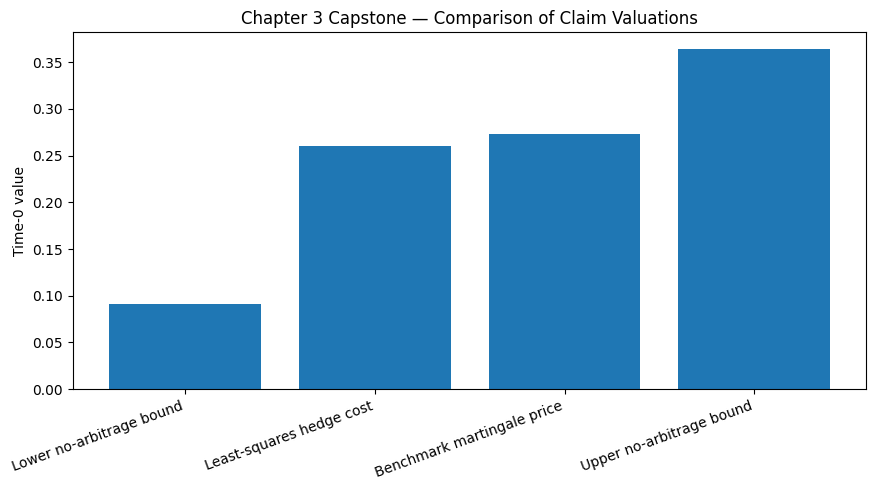

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(pricing_labels, pricing_values)

plt.ylabel("Time-0 value")
plt.title("Chapter 3 Capstone — Comparison of Claim Valuations")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Derivation and Interpretation of the Pricing Comparison

The four values obtained for the same contingent claim are

| Valuation | Exact value | Numerical value |
|---|---:|---:|
| Lower no-arbitrage bound | $\frac{1}{11}$ | $0.09091$ |
| Least-squares hedge cost | $\frac{20}{77}$ | $0.25974$ |
| Benchmark martingale price | $\frac{3}{11}$ | $0.27273$ |
| Upper no-arbitrage bound | $\frac{4}{11}$ | $0.36364$ |

To compare them using a common denominator, note that

$$
\frac{1}{11}
=
\frac{7}{77},
$$

$$
\frac{3}{11}
=
\frac{21}{77},
$$

and

$$
\frac{4}{11}
=
\frac{28}{77}.
$$

Therefore,

$$
\boxed{
\frac{7}{77}
<
\frac{20}{77}
<
\frac{21}{77}
<
\frac{28}{77}
}
$$

or equivalently,

$$
\boxed{
\frac{1}{11}
<
\frac{20}{77}
<
\frac{3}{11}
<
\frac{4}{11}.
}
$$

Thus, both interior comparison values satisfy the no-arbitrage bounds:

$$
\boxed{
C_{0,\min}
<
C_0^{LS}
<
C_0^{\mathrm{bench}}
<
C_{0,\max}.
}
$$

---

#### 1. Lower No-Arbitrage Bound

The lower bound is

$$
C_{0,\min}
=
\frac{1}{11}
\approx0.09091.
$$

This value is generated by the endpoint martingale measure

$$
Q_{\min}
=
\left(
\frac{1}{10},
\frac{9}{10},
0
\right).
$$

For the up-state Arrow-Debreu claim,

$$
C_1=(1,0,0),
$$

the claim pays only in the Up state. The lower limiting martingale measure
assigns the smallest Up-state probability in the closed nonnegative family,

$$
q_u=\frac{1}{10},
$$

to that state.

Discounting gives

$$
C_{0,\min}
=
\frac{10}{11}
\left(
\frac{1}{10}
\right)
=
\frac{1}{11}.
$$

This is the infimum of the arbitrage-free price set, not an admissible
trading price. The endpoint measure assigns zero probability to the possible
Down state, and the lower-endpoint trade verified in Part 3 demonstrates
the resulting arbitrage.

---

#### 2. Least-Squares Hedge Cost

The least-squares hedge cost is

$$
C_0^{LS}
=
\frac{20}{77}
\approx0.25974.
$$

This value comes from an entirely different calculation.

The least-squares portfolio

$$
\hat{\phi}
=
\begin{pmatrix}
-\frac{1}{22}\\
\frac{1}{14}
\end{pmatrix}
$$

is chosen to minimize

$$
\|C_1-M\phi\|_2^2.
$$

Its time-$0$ setup cost is

$$
C_0^{LS}
=
M_0^\top\hat{\phi}
=
\frac{20}{77}.
$$

Thus,

$$
\boxed{
C_0^{LS}
\text{ is generated by a hedging criterion rather than by selecting }Q.
}
$$

The fact that this value lies inside the no-arbitrage interval is important:

$$
\frac{1}{11}
<
\frac{20}{77}
<
\frac{4}{11}.
$$

Therefore, although least squares does not itself derive the no-arbitrage
price interval, the resulting hedge cost is compatible with that interval in
this example.

---

#### 3. Martingale Measure Corresponding to the Least-Squares Cost

Because every price inside the no-arbitrage interval is generated by at least
one admissible martingale measure, it is possible to determine which Up-state
martingale probability would produce the least-squares hedge cost as a claim
price.

For the claim,

$$
C_0(q)
=
\frac{10}{11}q.
$$

Set this equal to the least-squares hedge cost:

$$
\frac{10}{11}q
=
\frac{20}{77}.
$$

Solving for $q$ gives

$$
q
=
\frac{11}{10}
\left(
\frac{20}{77}
\right)
=
\frac{2}{7}.
$$

This satisfies

$$
\frac{1}{10}
<
\frac{2}{7}
<
\frac{2}{5},
$$

so it is admissible.

Substituting

$$
q=\frac{2}{7}
$$

into the martingale-measure family gives

$$
q_u
=
\frac{2}{7},
$$

$$
q_m
=
\frac{6}{5}
-
3\left(\frac{2}{7}\right)
=
\frac{12}{35},
$$

and

$$
q_d
=
2\left(\frac{2}{7}\right)
-
\frac{1}{5}
=
\frac{13}{35}.
$$

Therefore,

$$
Q_{LS}
=
\left(
\frac{2}{7},
\frac{12}{35},
\frac{13}{35}
\right).
$$

Under this martingale measure,

$$
\frac{1}{1+i}
E^{Q_{LS}}[C_1]
=
\frac{20}{77}
=
C_0^{LS}.
$$

This does **not** mean that least squares selected this martingale measure as
part of its optimization.

Rather, it shows that the numerical hedge cost happens to correspond to one
member of the independently derived martingale-measure pricing family.

---

#### 4. Benchmark Martingale Price

The benchmark price is

$$
C_0^{\mathrm{bench}}
=
\frac{3}{11}
=
\frac{21}{77}
\approx0.27273.
$$

It is generated by the explicitly selected benchmark measure

$$
Q_{\mathrm{bench}}
=
\left(
\frac{3}{10},
\frac{3}{10},
\frac{2}{5}
\right).
$$

Its difference from the least-squares hedge cost is

$$
C_0^{\mathrm{bench}}
-
C_0^{LS}
=
\frac{21}{77}
-
\frac{20}{77}
=
\frac{1}{77}.
$$

Therefore,

$$
\boxed{
C_0^{\mathrm{bench}}
-
C_0^{LS}
=
\frac{1}{77}
\approx0.01299.
}
$$

The numerical closeness of these two values does not make them theoretically
equivalent.

They arise from different rules:

- least squares minimizes payoff replication error;
- the benchmark price discounts the claim expectation under a chosen
  martingale measure.

---

#### 5. Upper No-Arbitrage Bound

The upper bound is

$$
C_{0,\max}
=
\frac{4}{11}
\approx0.36364.
$$

It is produced by the endpoint martingale measure

$$
Q_{\max}
=
\left(
\frac{2}{5},
0,
\frac{3}{5}
\right).
$$

This limiting measure assigns the largest Up-state probability in the closed
nonnegative martingale-measure family,

$$
q_u=\frac{2}{5},
$$

to the only state in which the claim pays.

Therefore,

$$
C_{0,\max}
=
\frac{10}{11}
\left(
\frac{2}{5}
\right)
=
\frac{4}{11}.
$$

This is the supremum of the arbitrage-free price set, not an admissible
trading price. The endpoint measure assigns zero probability to the possible
Middle state, and the upper-endpoint trade verified in Part 3 demonstrates
the resulting arbitrage.

---

#### 6. Width of the No-Arbitrage Interval

The total width of the price interval is

$$
C_{0,\max}
-
C_{0,\min}
=
\frac{4}{11}
-
\frac{1}{11}
=
\frac{3}{11}.
$$

Hence,

$$
\boxed{
C_{0,\max}
-
C_{0,\min}
=
\frac{3}{11}
\approx0.27273.
}
$$

This nonzero width is a direct numerical manifestation of the pricing
indeterminacy created by market incompleteness.

The traded assets restrict the price substantially, but they do not collapse
the admissible set to a single value.

---

#### 7. What the Bar Chart Shows

The bar chart makes the ordering of the four values visible:

$$
C_{0,\min}
<
C_0^{LS}
<
C_0^{\mathrm{bench}}
<
C_{0,\max}.
$$

The first and fourth bars are fundamentally different from the two interior
bars.

The lower and upper values are **limiting bounds**: the infimum and supremum
of the prices generated by equivalent martingale measures. The endpoint
prices themselves are excluded from the arbitrage-free trading-price set.

By contrast,

$$
C_0^{LS}
$$

is a hedge cost generated by a least-squares optimization rule, while

$$
C_0^{\mathrm{bench}}
$$

is one point valuation generated by an explicitly selected martingale
measure.

The graph therefore compares numerical values, but it should not be read as
saying that all four quantities have the same theoretical meaning.

---

#### 8. Central Financial Interpretation

The comparison illustrates the central pricing consequence of an incomplete
market.

For an attainable claim, exact replication would produce a unique portfolio
and a unique no-arbitrage price.

For the present claim,

$$
C_1\notin\operatorname{col}(M),
$$

so exact replication is impossible.

No-arbitrage therefore supplies an open interval of admissible trading prices,

$$
\boxed{
\frac{1}{11}
<
C_0
<
\frac{4}{11},
}
$$

rather than a single forced price. The endpoints remain the limiting
lower and upper bounds, but neither is included.

Additional criteria can then select or generate particular values inside that
range.

In this capstone:

$$
\boxed{
C_0^{LS}
=
\frac{20}{77}
}
$$

comes from minimizing hedging error, while

$$
\boxed{
C_0^{\mathrm{bench}}
=
\frac{3}{11}
}
$$

comes from choosing one admissible martingale measure.

Thus,

$$
\boxed{
\text{no arbitrage restricts the valuation set, while an additional rule is
needed to select a particular valuation.}
}
$$

This distinction is one of the main economic consequences of market
incompleteness.

---

#### 9. Transition to the Hedging-Error Analysis

The pricing comparison answers how different admissible rules value the claim
today.

It does not yet show **where** the least-squares hedge fails across future
states.

The next section therefore returns to the residual

$$
e=C_1-M\hat{\phi}
$$

and visualizes the state-by-state replication errors.

This shifts the focus from

$$
\text{pricing ambiguity}
$$

to

$$
\text{unhedgeable payoff risk}.
$$

## Part 6 — Visualizing the Replication Errors

The least-squares portfolio minimizes the total squared replication error, but
it does not eliminate the error in each state.

From Part 2,

$$
e
=
C_1-M\hat{\phi}
=
\begin{pmatrix}
\frac{1}{14}\\
-\frac{3}{14}\\
\frac{1}{7}
\end{pmatrix}
\approx
\begin{pmatrix}
0.07143\\
-0.21429\\
0.14286
\end{pmatrix}.
$$

Because the residual is defined as

$$
e=C_1-M\hat{\phi},
$$

its sign has a direct financial interpretation:

- $e_i>0$: the hedge payoff is below the claim payoff in state $i$;
- $e_i<0$: the hedge payoff is above the claim payoff in state $i$;
- $e_i=0$: the hedge exactly matches the claim payoff in state $i$.

The absolute residual

$$
|e_i|
$$

measures the magnitude of the state-specific hedging error regardless of
whether the hedge under- or over-replicates the claim.

This section compares both the signed and absolute replication errors across
the Up, Middle, and Down states.

In [10]:
state_errors = ls_residual
absolute_errors = np.abs(state_errors)

print(f"{'State':<10} {'Residual':>12} {'Absolute error':>16}")
print("-" * 40)

for state, error, abs_error in zip(states, state_errors, absolute_errors):
    print(f"{state:<10} {error:>12.5f} {abs_error:>16.5f}")

largest_error_index = np.argmax(absolute_errors)

print()
print("Largest absolute hedging error:", states[largest_error_index])
print("Magnitude:", absolute_errors[largest_error_index])

State          Residual   Absolute error
----------------------------------------
Up              0.07143          0.07143
Middle         -0.21429          0.21429
Down            0.14286          0.14286

Largest absolute hedging error: Middle
Magnitude: 0.21428571428571433


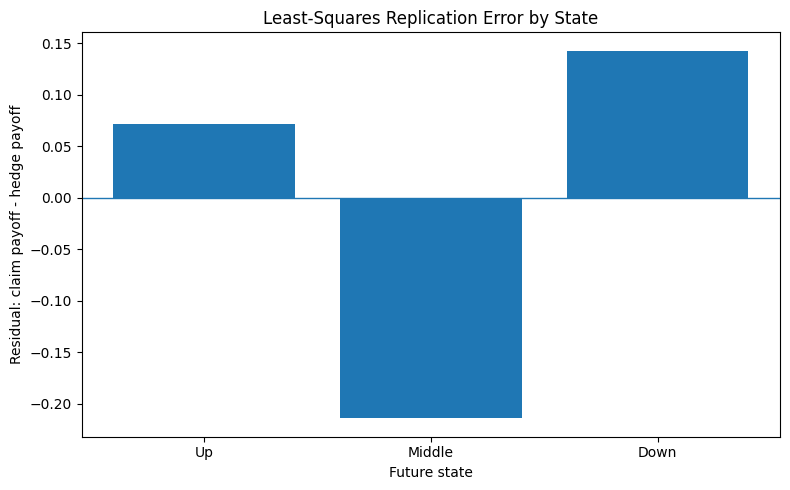

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(states, state_errors)

plt.axhline(0.0, linewidth=1)

plt.xlabel("Future state")
plt.ylabel("Residual: claim payoff - hedge payoff")
plt.title("Least-Squares Replication Error by State")

plt.tight_layout()
plt.show()

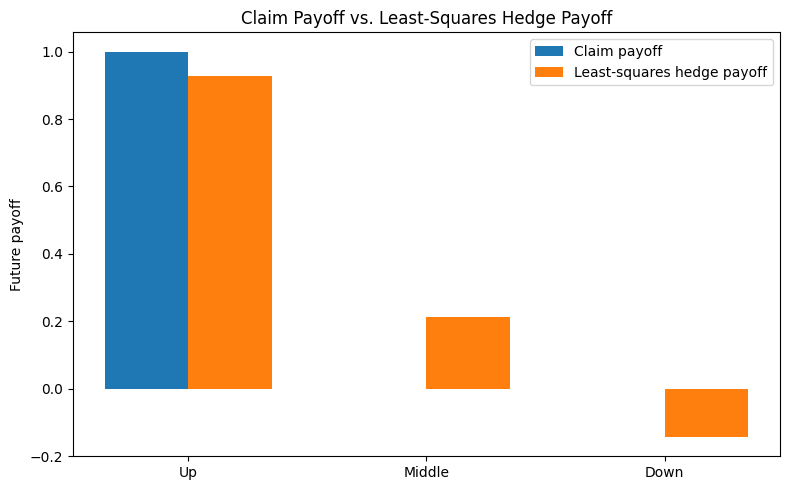

In [12]:
x = np.arange(len(states))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width / 2, C1, width, label="Claim payoff")
plt.bar(x + width / 2, ls_payoff, width, label="Least-squares hedge payoff")

plt.xticks(x, states)
plt.ylabel("Future payoff")
plt.title("Claim Payoff vs. Least-Squares Hedge Payoff")
plt.legend()

plt.tight_layout()
plt.show()

### Derivation and Interpretation of the Replication Errors

The least-squares residual is

$$
e
=
C_1-M\hat{\phi}
=
\begin{pmatrix}
\frac{1}{14}\\
-\frac{3}{14}\\
\frac{1}{7}
\end{pmatrix}
\approx
\begin{pmatrix}
0.07143\\
-0.21429\\
0.14286
\end{pmatrix}.
$$

The Python calculation confirms the state-by-state errors:

| State | Residual | Absolute error |
|---|---:|---:|
| Up | $0.07143$ | $0.07143$ |
| Middle | $-0.21429$ | $0.21429$ |
| Down | $0.14286$ | $0.14286$ |

The largest absolute hedging error occurs in the **Middle state**:

$$
\boxed{
|e_m|
=
\frac{3}{14}
\approx
0.21429
}.
$$

---

#### 1. Interpreting the Sign of the Residual

The residual is defined as

$$
e=C_1-M\hat{\phi}.
$$

Therefore, its sign compares the claim payoff with the hedge payoff.

If

$$
e_i>0,
$$

then

$$
C_{1,i}>(M\hat{\phi})_i,
$$

so the hedge **under-replicates** the claim in that state.

If

$$
e_i<0,
$$

then

$$
C_{1,i}<(M\hat{\phi})_i,
$$

so the hedge **over-replicates** the claim.

For the present claim,

$$
C_1
=
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix},
$$

while the least-squares hedge produces

$$
M\hat{\phi}
=
\begin{pmatrix}
\frac{13}{14}\\
\frac{3}{14}\\
-\frac{1}{7}
\end{pmatrix}.
$$

Thus, the three state-specific errors can be understood directly from the
difference between these two payoff vectors.

---

#### 2. Up-State Error

In the Up state,

$$
C_{1,u}=1,
$$

while the hedge pays

$$
(M\hat{\phi})_u
=
\frac{13}{14}.
$$

Therefore,

$$
e_u
=
1-\frac{13}{14}
=
\frac{1}{14}
\approx0.07143.
$$

Hence,

$$
\boxed{
e_u>0
}
$$

and the hedge **under-replicates** the claim in the Up state.

The hedge provides approximately

$$
0.92857
$$

when the claim requires

$$
1.
$$

The shortfall is therefore approximately

$$
0.07143.
$$

---

#### 3. Middle-State Error

In the Middle state, the claim pays

$$
C_{1,m}=0,
$$

while the hedge pays

$$
(M\hat{\phi})_m
=
\frac{3}{14}.
$$

Therefore,

$$
e_m
=
0-\frac{3}{14}
=
-\frac{3}{14}
\approx-0.21429.
$$

Hence,

$$
\boxed{
e_m<0
}
$$

and the hedge **over-replicates** the claim in the Middle state.

Although the claim requires no payment in this state, the least-squares
portfolio produces a positive payoff of approximately

$$
0.21429.
$$

The magnitude of this mismatch is

$$
\boxed{
|e_m|
=
\frac{3}{14}
\approx0.21429,
}
$$

which is the largest of the three state-specific errors.

---

#### 4. Down-State Error

In the Down state, the claim again pays

$$
C_{1,d}=0.
$$

The least-squares hedge produces

$$
(M\hat{\phi})_d
=
-\frac{1}{7}.
$$

Therefore,

$$
e_d
=
0-\left(-\frac{1}{7}\right)
=
\frac{1}{7}
\approx0.14286.
$$

Hence,

$$
\boxed{
e_d>0
}
$$

and the hedge lies below the claim payoff in the Down state.

The negative hedge payoff means that the bond-stock portfolio itself loses

$$
\frac{1}{7}
$$

in this state, while the claim has a zero payoff.

The resulting mismatch is therefore

$$
\boxed{
|e_d|
=
\frac{1}{7}
\approx0.14286.
}
$$

---

#### 5. Ranking the State-Specific Hedging Errors

The absolute errors are

$$
|e_u|
=
\frac{1}{14},
$$

$$
|e_m|
=
\frac{3}{14},
$$

and

$$
|e_d|
=
\frac{1}{7}
=
\frac{2}{14}.
$$

Therefore,

$$
\boxed{
|e_u|
<
|e_d|
<
|e_m|.
}
$$

Numerically,

$$
0.07143
<
0.14286
<
0.21429.
$$

The Middle state is therefore the state in which the least-squares hedge
deviates most strongly from the target claim.

---

#### 6. Contribution of Each State to the Squared Replication Error

Least squares minimizes the sum of squared residuals, so it is useful to
examine not only the absolute errors but also their squared contributions.

For the Up state,

$$
e_u^2
=
\left(\frac{1}{14}\right)^2
=
\frac{1}{196}.
$$

For the Middle state,

$$
e_m^2
=
\left(-\frac{3}{14}\right)^2
=
\frac{9}{196}.
$$

For the Down state,

$$
e_d^2
=
\left(\frac{1}{7}\right)^2
=
\frac{4}{196}.
$$

The total squared error is therefore

$$
\|e\|_2^2
=
\frac{1}{196}
+
\frac{9}{196}
+
\frac{4}{196}
=
\frac{14}{196}
=
\frac{1}{14}.
$$

The fraction of total squared replication error contributed by each state is
therefore:

**Up**

$$
\frac{1/196}{1/14}
=
\frac{1}{14}
\approx7.14\%.
$$

**Middle**

$$
\frac{9/196}{1/14}
=
\frac{9}{14}
\approx64.29\%.
$$

**Down**

$$
\frac{4/196}{1/14}
=
\frac{2}{7}
\approx28.57\%.
$$

Thus,

$$
\boxed{
\text{the Middle state contributes approximately }64.29\%
\text{ of the total squared replication error.}
}
$$

This explains why the Middle-state mismatch is visually dominant in the
residual plot and quantitatively dominant in the least-squares objective.

---

#### 7. Interpretation of the Residual Plot

The first figure plots

$$
e_i=C_{1,i}-(M\hat{\phi})_i
$$

for each state.

The zero line separates under-replication from over-replication:

- bars above zero indicate that the hedge payoff is below the claim payoff;
- bars below zero indicate that the hedge payoff exceeds the claim payoff.

The plot therefore shows immediately that

- the Up state is under-replicated;
- the Middle state is over-replicated;
- the Down state is under-replicated.

The Middle-state bar has the greatest magnitude, confirming the numerical
calculation

$$
\boxed{
|e_m|
=
\frac{3}{14}.
}
$$

---

#### 8. Interpretation of the Claim-versus-Hedge Plot

The second figure compares the two payoff vectors directly:

$$
C_1
=
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix}
$$

and

$$
M\hat{\phi}
=
\begin{pmatrix}
\frac{13}{14}\\
\frac{3}{14}\\
-\frac{1}{7}
\end{pmatrix}.
$$

The plot shows where the residuals originate:

- in the **Up state**, the hedge nearly reproduces the claim but remains slightly
  below it;
- in the **Middle state**, the claim pays zero while the hedge produces a
  substantial positive payoff;
- in the **Down state**, the claim pays zero while the hedge produces a negative
  payoff.

Thus, the residual plot shows the **difference**, while the payoff-comparison
plot shows the **two underlying payoff vectors whose difference creates the
residual**.

---

#### 9. Why the Errors Must Balance Geometrically

From least-squares optimality,

$$
M^\top e=0.
$$

Because the first column of $M$ is the bond payoff vector

$$
B_1
=
\begin{pmatrix}
11\\
11\\
11
\end{pmatrix},
$$

orthogonality to the bond implies

$$
B_1^\top e=0.
$$

Therefore,

$$
11(e_u+e_m+e_d)=0,
$$

so

$$
e_u+e_m+e_d=0.
$$

Indeed,

$$
\frac{1}{14}
-
\frac{3}{14}
+
\frac{1}{7}
=
\frac{1-3+2}{14}
=
0.
$$

The residual is also orthogonal to the stock payoff vector:

$$
S_1^\top e=0.
$$

Explicitly,

$$
20\left(\frac{1}{14}\right)
+
10\left(-\frac{3}{14}\right)
+
5\left(\frac{1}{7}\right)
=
0.
$$

Thus, the error pattern is not arbitrary.

The positive and negative residuals balance in exactly the way required for
the residual to be perpendicular to every payoff direction available from the
traded assets.

---

#### 10. Financial Interpretation

Least squares does not attempt to avoid every possible state-specific
shortfall.

Instead, it solves a global optimization problem:

$$
\min_{\phi}
\sum_{i=1}^{3}
e_i^2.
$$

The resulting hedge therefore accepts

- a small shortfall in the Up state;
- a larger excess payoff in the Middle state;
- an intermediate shortfall in the Down state;

because this combination minimizes the total squared error across all three
states.

This is fundamentally different from **super-replication**, which would require

$$
M\phi\geq C_1
$$

state by state and would not permit a hedge payoff below the claim payoff in
any state.

Thus,

$$
\boxed{
\text{least squares minimizes overall approximation error rather than
guaranteeing state-by-state coverage.}
}
$$

The remaining residual is the unhedgeable payoff component created by market
incompleteness.

---

#### 11. Transition to a Designed Claim

For the original up-state claim, the largest replication error occurs in the
Middle state.

The final experimental step is to move beyond this particular claim and
deliberately construct a new payoff vector whose least-squares residual has an
especially revealing pattern.

This will show that the hedging-error structure is determined by the geometry
of the attainable payoff space, not merely by the specific numerical values of
the original Arrow-Debreu claim.

## Part 7 — Designing a Claim With a Surprising Error Pattern

The original up-state Arrow-Debreu claim already produced its largest
least-squares error in the Middle state.

Rather than choose another claim arbitrarily, I use the geometry of the
incomplete market to design one deliberately.

The attainable payoff space is

$$
\operatorname{col}(M)
=
\operatorname{span}\{B_1,S_1\}.
$$

Because

$$
M\in\mathbb{R}^{3\times2}
$$

has rank $2$, its column space is a two-dimensional subspace of
$\mathbb{R}^3$.

The orthogonal complement of this attainable space is therefore
one-dimensional.

A vector $n$ lies in this unhedgeable direction if

$$
M^\top n=0.
$$

Let

$$
n=
\begin{pmatrix}
n_u\\
n_m\\
n_d
\end{pmatrix}.
$$

Then

$$
M^\top n
=
\begin{pmatrix}
11 & 11 & 11\\
20 & 10 & 5
\end{pmatrix}
\begin{pmatrix}
n_u\\
n_m\\
n_d
\end{pmatrix}
=
\begin{pmatrix}
0\\
0
\end{pmatrix}.
$$

This gives

$$
n_u+n_m+n_d=0
$$

and

$$
20n_u+10n_m+5n_d=0.
$$

One nonzero solution is

$$
\boxed{
n=
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}.
}
$$

Thus,

$$
\operatorname{null}(M^\top)
=
\operatorname{span}
\left\{
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}
\right\}.
$$

The Middle-state component has the largest absolute coefficient:

$$
|-3|>|2|>|1|.
$$

This suggests that a claim concentrated in the Middle state should have a
particularly large projection onto the unhedgeable direction.

I therefore choose the middle-state Arrow-Debreu claim

$$
\boxed{
C_1^{\mathrm{mid}}
=
\begin{pmatrix}
0\\
1\\
0
\end{pmatrix}.
}
$$

This claim pays one unit only in the Middle state.

The objective is to compute its least-squares hedge and determine whether its
residual displays the anticipated large Middle-state error.

In [13]:
# Verify the one-dimensional unhedgeable direction
unhedgeable_direction = np.array([1.0, -3.0, 2.0])

orthogonality_check = M.T @ unhedgeable_direction

print("Unhedgeable direction:", unhedgeable_direction)
print("M.T @ unhedgeable_direction:", orthogonality_check)

# Middle-state Arrow-Debreu claim
C1_mid = np.array([0.0, 1.0, 0.0])

# Least-squares hedge
phi_mid, _, _, _ = np.linalg.lstsq(M, C1_mid, rcond=None)

mid_hedge_payoff = M @ phi_mid
mid_residual = C1_mid - mid_hedge_payoff

mid_absolute_errors = np.abs(mid_residual)
mid_residual_norm = np.linalg.norm(mid_residual)
mid_mse = np.mean(mid_residual ** 2)

largest_mid_error_index = np.argmax(mid_absolute_errors)

print()
print("Middle-state claim:", C1_mid)
print("Least-squares holdings:", phi_mid)
print("Least-squares hedge payoff:", mid_hedge_payoff)
print("Residual:", mid_residual)
print("Residual norm:", mid_residual_norm)
print("Mean squared error:", mid_mse)
print()
print(
    "Largest absolute error state:",
    states[largest_mid_error_index]
)
print(
    "Largest absolute error magnitude:",
    mid_absolute_errors[largest_mid_error_index]
)

Unhedgeable direction: [ 1. -3.  2.]
M.T @ unhedgeable_direction: [0. 0.]

Middle-state claim: [0. 1. 0.]
Least-squares holdings: [ 0.04545 -0.01429]
Least-squares hedge payoff: [0.21429 0.35714 0.42857]
Residual: [-0.21429  0.64286 -0.42857]
Residual norm: 0.8017837257372731
Mean squared error: 0.21428571428571427

Largest absolute error state: Middle
Largest absolute error magnitude: 0.6428571428571428


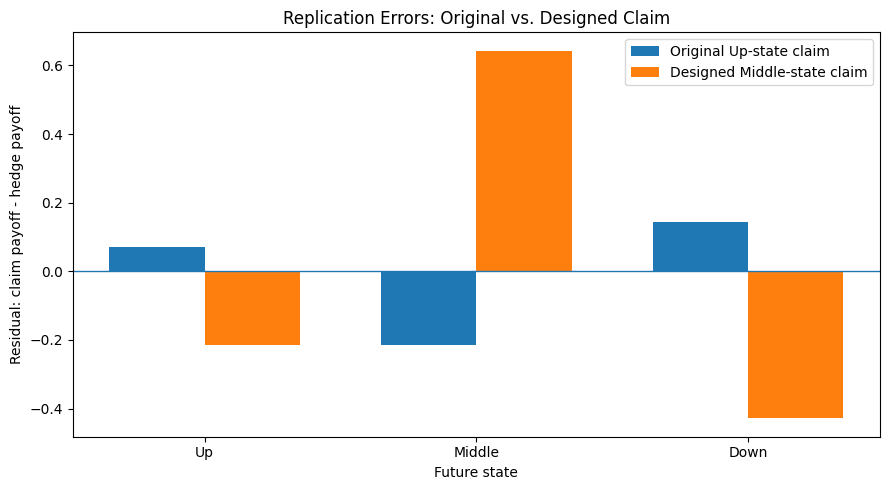

In [14]:
x = np.arange(len(states))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    ls_residual,
    width,
    label="Original Up-state claim"
)

plt.bar(
    x + width / 2,
    mid_residual,
    width,
    label="Designed Middle-state claim"
)

plt.axhline(0.0, linewidth=1)

plt.xticks(x, states)
plt.xlabel("Future state")
plt.ylabel("Residual: claim payoff - hedge payoff")
plt.title("Replication Errors: Original vs. Designed Claim")
plt.legend()

plt.tight_layout()
plt.show()

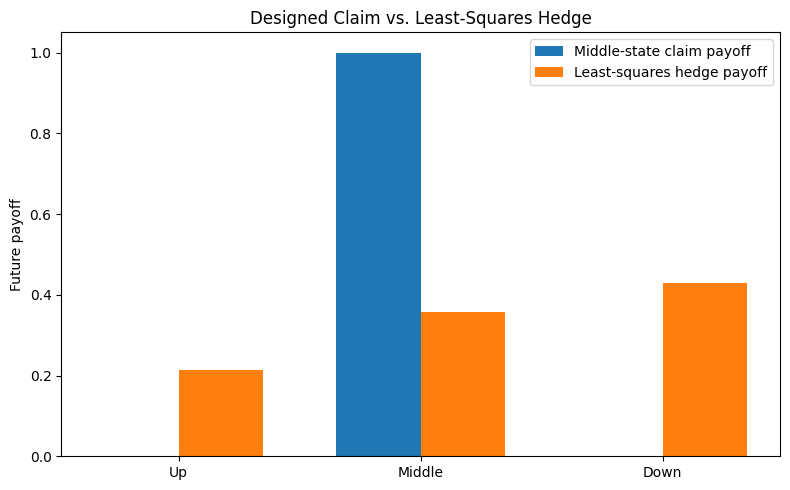

In [15]:
x = np.arange(len(states))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    C1_mid,
    width,
    label="Middle-state claim payoff"
)

plt.bar(
    x + width / 2,
    mid_hedge_payoff,
    width,
    label="Least-squares hedge payoff"
)

plt.xticks(x, states)
plt.ylabel("Future payoff")
plt.title("Designed Claim vs. Least-Squares Hedge")
plt.legend()

plt.tight_layout()
plt.show()

### Derivation and Interpretation of the Designed Claim

The designed claim is the middle-state Arrow-Debreu payoff

$$
C_1^{\mathrm{mid}}
=
\begin{pmatrix}
0\\
1\\
0
\end{pmatrix}.
$$

It pays one unit only in the Middle state.

The purpose of this experiment is not merely to try another claim. The claim
was chosen using the geometry of the incomplete market.

Part 6 showed that the one-dimensional unhedgeable direction is

$$
n
=
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix},
$$

with

$$
M^\top n=0.
$$

Because the Middle-state component has the largest absolute coefficient,

$$
|-3|>|2|>|1|,
$$

a claim concentrated in the Middle state should have a particularly large
projection onto the unhedgeable direction.

The numerical results confirm this prediction.

---

#### 1. Verifying the Unhedgeable Direction

The market payoff matrix is

$$
M
=
\begin{pmatrix}
11 & 20\\
11 & 10\\
11 & 5
\end{pmatrix}.
$$

The proposed unhedgeable direction is

$$
n
=
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}.
$$

Multiplying by $M^\top$ gives

$$
M^\top n
=
\begin{pmatrix}
11 & 11 & 11\\
20 & 10 & 5
\end{pmatrix}
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}.
$$

For the bond direction,

$$
11(1)+11(-3)+11(2)
=
11-33+22
=
0.
$$

For the stock direction,

$$
20(1)+10(-3)+5(2)
=
20-30+10
=
0.
$$

Therefore,

$$
\boxed{
M^\top n
=
\begin{pmatrix}
0\\
0
\end{pmatrix}.
}
$$

Thus,

$$
n\in\operatorname{null}(M^\top).
$$

Since the attainable payoff space has dimension $2$ inside
$\mathbb{R}^3$, its orthogonal complement has dimension $1$.

Therefore,

$$
\boxed{
\operatorname{null}(M^\top)
=
\operatorname{span}
\left\{
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}
\right\}.
}
$$

This vector describes the unique payoff direction that cannot be generated by
the traded bond and stock.

---

#### 2. Least-Squares Portfolio for the Middle-State Claim

The least-squares problem is

$$
\hat{\phi}^{\mathrm{mid}}
=
\arg\min_{\phi}
\left\|
C_1^{\mathrm{mid}}-M\phi
\right\|_2^2.
$$

The Python solver returns

$$
\hat{\phi}^{\mathrm{mid}}
\approx
\begin{pmatrix}
0.04545\\
-0.01429
\end{pmatrix}.
$$

In exact form,

$$
\boxed{
\hat{\phi}^{\mathrm{mid}}
=
\begin{pmatrix}
\frac{1}{22}\\
-\frac{1}{70}
\end{pmatrix}.
}
$$

Financially, this hedge consists of

- a long position of $\frac{1}{22}$ of the bond;
- a short position of $\frac{1}{70}$ of the stock.

These positions minimize the total squared replication error for the
middle-state claim.

---

#### 3. Attainable Payoff Produced by the Hedge

Using the exact holdings,

$$
M\hat{\phi}^{\mathrm{mid}}
=
\begin{pmatrix}
11 & 20\\
11 & 10\\
11 & 5
\end{pmatrix}
\begin{pmatrix}
\frac{1}{22}\\
-\frac{1}{70}
\end{pmatrix}.
$$

In the Up state,

$$
11\left(\frac{1}{22}\right)
-
20\left(\frac{1}{70}\right)
=
\frac{1}{2}
-
\frac{2}{7}
=
\frac{3}{14}.
$$

In the Middle state,

$$
11\left(\frac{1}{22}\right)
-
10\left(\frac{1}{70}\right)
=
\frac{1}{2}
-
\frac{1}{7}
=
\frac{5}{14}.
$$

In the Down state,

$$
11\left(\frac{1}{22}\right)
-
5\left(\frac{1}{70}\right)
=
\frac{1}{2}
-
\frac{1}{14}
=
\frac{3}{7}.
$$

Therefore,

$$
\boxed{
M\hat{\phi}^{\mathrm{mid}}
=
\begin{pmatrix}
\frac{3}{14}\\
\frac{5}{14}\\
\frac{3}{7}
\end{pmatrix}
}
$$

or numerically,

$$
M\hat{\phi}^{\mathrm{mid}}
\approx
\begin{pmatrix}
0.21429\\
0.35714\\
0.42857
\end{pmatrix}.
$$

The hedge therefore cannot reproduce the sharp payoff pattern

$$
(0,1,0)
$$

using only the flat bond payoff and the monotonic stock payoff.

---

#### 4. Residual of the Designed Claim

The residual is

$$
e^{\mathrm{mid}}
=
C_1^{\mathrm{mid}}
-
M\hat{\phi}^{\mathrm{mid}}.
$$

Therefore,

$$
e^{\mathrm{mid}}
=
\begin{pmatrix}
0\\
1\\
0
\end{pmatrix}
-
\begin{pmatrix}
\frac{3}{14}\\
\frac{5}{14}\\
\frac{3}{7}
\end{pmatrix}.
$$

Hence,

$$
\boxed{
e^{\mathrm{mid}}
=
\begin{pmatrix}
-\frac{3}{14}\\
\frac{9}{14}\\
-\frac{3}{7}
\end{pmatrix}
}
$$

or numerically,

$$
e^{\mathrm{mid}}
\approx
\begin{pmatrix}
-0.21429\\
0.64286\\
-0.42857
\end{pmatrix}.
$$

State by state:

- **Up:** the hedge exceeds the claim by

  $$
  \frac{3}{14}
  \approx0.21429;
  $$

- **Middle:** the hedge falls short of the claim by

  $$
  \frac{9}{14}
  \approx0.64286;
  $$

- **Down:** the hedge exceeds the claim by

  $$
  \frac{3}{7}
  \approx0.42857.
  $$

The largest absolute replication error is therefore

$$
\boxed{
|e_m^{\mathrm{mid}}|
=
\frac{9}{14}
\approx0.64286.
}
$$

This occurs exactly in the Middle state, as anticipated from the
unhedgeable direction.

---

#### 5. The Residual Is Exactly Aligned With the Unhedgeable Direction

Recall that

$$
n
=
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}.
$$

The designed residual can be written as

$$
e^{\mathrm{mid}}
=
-\frac{3}{14}
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}.
$$

Therefore,

$$
\boxed{
e^{\mathrm{mid}}
=
-\frac{3}{14}n.
}
$$

This is not a numerical coincidence.

Every least-squares residual must satisfy

$$
M^\top e=0.
$$

Since

$$
\operatorname{null}(M^\top)
$$

is one-dimensional, every residual must be a scalar multiple of the same
unhedgeable direction $n$.

Thus, the original claim and the designed claim do not have unrelated error
patterns.

They expose the same missing payoff direction with different magnitudes and
signs.

---

#### 6. Projection Formula for the Unhedgeable Component

Because

$$
\operatorname{null}(M^\top)
=
\operatorname{span}\{n\},
$$

the unhedgeable component of any claim $C$ is its orthogonal projection onto
$n$:

$$
e
=
\frac{C^\top n}{n^\top n}n.
$$

For

$$
n=
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix},
$$

we have

$$
n^\top n
=
1^2+(-3)^2+2^2
=
14.
$$

For the designed claim,

$$
C_1^{\mathrm{mid}}
=
\begin{pmatrix}
0\\
1\\
0
\end{pmatrix},
$$

so

$$
(C_1^{\mathrm{mid}})^\top n
=
-3.
$$

Therefore,

$$
e^{\mathrm{mid}}
=
\frac{-3}{14}n.
$$

Hence,

$$
e^{\mathrm{mid}}
=
-\frac{3}{14}
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}
=
\begin{pmatrix}
-\frac{3}{14}\\
\frac{9}{14}\\
-\frac{3}{7}
\end{pmatrix}.
$$

This reproduces the least-squares residual exactly.

Thus, the large Middle-state error can be predicted directly from the geometry
of the claim before running the numerical least-squares solver.

---

#### 7. Why the Middle-State Claim Produces a Much Larger Error

For the original Up-state claim,

$$
C_1^{\mathrm{up}}
=
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix}.
$$

Its projection onto the unhedgeable direction is determined by

$$
(C_1^{\mathrm{up}})^\top n
=
1.
$$

Therefore,

$$
e^{\mathrm{up}}
=
\frac{1}{14}n.
$$

For the Middle-state claim,

$$
(C_1^{\mathrm{mid}})^\top n
=
-3,
$$

so

$$
e^{\mathrm{mid}}
=
-\frac{3}{14}n.
$$

Hence,

$$
\boxed{
e^{\mathrm{mid}}
=
-3e^{\mathrm{up}}.
}
$$

The designed residual therefore has three times the Euclidean magnitude of the
original residual:

$$
\|e^{\mathrm{mid}}\|_2
=
3\|e^{\mathrm{up}}\|_2.
$$

Since

$$
\|e^{\mathrm{up}}\|_2
=
\frac{1}{\sqrt{14}},
$$

we obtain

$$
\boxed{
\|e^{\mathrm{mid}}\|_2
=
\frac{3}{\sqrt{14}}
\approx0.80178.
}
$$

This agrees with the Python output.

---

#### 8. Mean Squared Error

The squared residual norm is

$$
\|e^{\mathrm{mid}}\|_2^2
=
\left(
\frac{3}{\sqrt{14}}
\right)^2
=
\frac{9}{14}.
$$

The mean squared error is therefore

$$
\mathrm{MSE}_{\mathrm{mid}}
=
\frac{1}{3}
\|e^{\mathrm{mid}}\|_2^2.
$$

Hence,

$$
\mathrm{MSE}_{\mathrm{mid}}
=
\frac{1}{3}
\left(
\frac{9}{14}
\right)
=
\frac{3}{14}.
$$

Thus,

$$
\boxed{
\mathrm{MSE}_{\mathrm{mid}}
=
\frac{3}{14}
\approx0.21429.
}
$$

For the original Up-state claim,

$$
\mathrm{MSE}_{\mathrm{up}}
=
\frac{1}{42}.
$$

Therefore,

$$
\frac{\mathrm{MSE}_{\mathrm{mid}}}
{\mathrm{MSE}_{\mathrm{up}}}
=
\frac{3/14}{1/42}
=
9.
$$

Hence,

$$
\boxed{
\mathrm{MSE}_{\mathrm{mid}}
=
9\,\mathrm{MSE}_{\mathrm{up}}.
}
$$

The designed claim therefore creates three times the residual magnitude and
nine times the mean squared replication error of the original claim.

---

#### 9. Interpretation of the Comparison Plot

The residual comparison plot places

$$
e^{\mathrm{up}}
=
\frac{1}{14}
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}
$$

beside

$$
e^{\mathrm{mid}}
=
-\frac{3}{14}
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}.
$$

The two patterns therefore have the same underlying geometric structure:

- their signs are reversed;
- the designed claim has three times the magnitude.

This makes the one-dimensional nature of the unhedgeable payoff space visible.

Although the claims themselves are different, their unhedgeable components
must lie along the same direction because the market is missing exactly one
independent payoff dimension.

---

#### 10. Interpretation of the Claim-versus-Hedge Plot

The designed claim has the sharply concentrated payoff

$$
(0,1,0).
$$

By contrast, the bond and stock generate payoff patterns through combinations
of

$$
(11,11,11)
$$

and

$$
(20,10,5).
$$

The bond contributes a constant payoff across states, while the stock payoff
declines from Up to Middle to Down.

A sharp Middle-state spike is therefore difficult to reproduce using only
these two payoff patterns.

The least-squares portfolio responds by producing the smoother attainable
payoff

$$
\left(
\frac{3}{14},
\frac{5}{14},
\frac{3}{7}
\right),
$$

which misses the intended Middle-state concentration substantially.

The plot therefore gives a direct financial visualization of market
incompleteness:

$$
\boxed{
\text{the traded assets do not provide enough independent payoff patterns to
isolate the Middle state.}
}
$$

---

#### 11. Central Insight of the Designed-Claim Experiment

The surprising residual pattern was not discovered by random trial and error.

It was designed from the geometry of the market.

Because

$$
\operatorname{null}(M^\top)
=
\operatorname{span}
\left\{
(1,-3,2)^\top
\right\},
$$

the coefficient of each state in this vector indicates how strongly a
state-concentrated claim overlaps with the market's missing payoff direction.

The Middle state has the largest coefficient in absolute value:

$$
|-3|>|2|>|1|.
$$

The Middle-state Arrow-Debreu claim therefore has the largest projection onto
the unhedgeable direction among the three unit state claims.

Its unusually large residual is consequently a structural feature of the
market geometry, not an accident of numerical optimization.

Thus,

$$
\boxed{
\text{market incompleteness is visible both algebraically through rank and
geometrically through the residual projection.}
}
$$

This completes the designed-claim experiment and sets up the final synthesis of
the capstone.

## Part 8 — Financial Interpretation and Conclusions

This capstone examined pricing and hedging in a two-date, three-state market
with only two traded assets: a risk-free bond and a risky stock.

The central feature of the model is **market incompleteness**.

The traded payoff matrix is

$$
M
=
\begin{pmatrix}
11 & 20\\
11 & 10\\
11 & 5
\end{pmatrix},
$$

with

$$
\operatorname{rank}(M)=2.
$$

Because contingent claims live in the three-dimensional payoff space
$\mathbb{R}^3$, the two independent traded payoff vectors span only a
two-dimensional subspace.

Therefore,

$$
\boxed{
\operatorname{col}(M)
\subsetneq
\mathbb{R}^3.
}
$$

Some claims lie outside the attainable payoff space and cannot be replicated
exactly using the traded bond and stock.

The up-state Arrow-Debreu claim

$$
C_1
=
\begin{pmatrix}
1\\
0\\
0
\end{pmatrix}
$$

is one such claim.

---

### 1. Incompleteness Appears First as a Replication Failure

The attainability test gave

$$
\operatorname{rank}(M)=2,
$$

while

$$
\operatorname{rank}([M\mid C_1])=3.
$$

Therefore,

$$
C_1\notin\operatorname{col}(M),
$$

and

$$
M\phi=C_1
$$

has no exact solution.

Thus,

$$
\boxed{
\text{the claim is unattainable.}
}
$$

This is the first consequence of market incompleteness.

There is no bond-stock portfolio whose future payoff exactly reproduces the
claim in all three states.

---

### 2. Least Squares Converts Exact Replication Into Approximate Hedging

Because exact replication fails, the hedging problem becomes

$$
\hat{\phi}
=
\arg\min_{\phi}
\|C_1-M\phi\|_2^2.
$$

The solution is

$$
\boxed{
\hat{\phi}
=
\begin{pmatrix}
-\frac{1}{22}\\
\frac{1}{14}
\end{pmatrix}
}.
$$

This portfolio produces

$$
M\hat{\phi}
=
\begin{pmatrix}
\frac{13}{14}\\
\frac{3}{14}\\
-\frac{1}{7}
\end{pmatrix},
$$

leaving the residual

$$
e
=
C_1-M\hat{\phi}
=
\begin{pmatrix}
\frac{1}{14}\\
-\frac{3}{14}\\
\frac{1}{7}
\end{pmatrix}.
$$

The residual is nonzero, so the hedge does not eliminate the payoff risk.

Its norm is

$$
\boxed{
\|e\|_2
=
\frac{1}{\sqrt{14}}
\approx0.26726
}
$$

and its mean squared replication error is

$$
\boxed{
\mathrm{MSE}
=
\frac{1}{42}
\approx0.02381.
}
$$

The least-squares hedge therefore solves an approximation problem rather than a
replication problem.

---

### 3. The Geometry Explains the Least-Squares Solution

Least-squares optimality implies

$$
M^\top e=0.
$$

Therefore, the residual is orthogonal to every payoff direction generated by
the traded assets.

Geometrically,

$$
M\hat{\phi}
$$

is the orthogonal projection of the unattainable claim onto the attainable
payoff space.

The claim can therefore be decomposed as

$$
\boxed{
C_1
=
M\hat{\phi}
+
e,
}
$$

where

- $M\hat{\phi}$ is the attainable component;
- $e$ is the unhedgeable component.

This gives a geometric interpretation of market incompleteness:

$$
\boxed{
\text{the residual is the part of the claim lying outside the traded-payoff
span.}
}
$$

---

### 4. Approximate Hedging Does Not Restore a Unique Price

The least-squares hedge costs

$$
\boxed{
C_0^{LS}
=
\frac{20}{77}
\approx0.25974.
}
$$

This value is economically meaningful because it is the cost of the portfolio
selected by the least-squares criterion.

However, it is not a uniquely forced arbitrage-free price of the claim.

Exact replication would allow the no-arbitrage principle to identify the claim
price with the cost of the replicating portfolio.

Here,

$$
C_1\notin\operatorname{col}(M),
$$

so no exact replicating portfolio exists.

Therefore,

$$
\boxed{
\text{least-squares hedge cost}
\neq
\text{uniquely determined claim price}.
}
$$

The distinction between **hedging rule** and **pricing rule** is essential in
an incomplete market.

---

### 5. Incompleteness Also Appears as Nonuniqueness of Martingale Measures

With all three states physically possible, the equivalent martingale
measures form the family

$$
Q(q)
=
\left(
q,\;
\frac{6}{5}-3q,\;
2q-\frac{1}{5}
\right),
$$

with

$$
\boxed{
\frac{1}{10}
<
q
<
\frac{2}{5}.
}
$$

Thus, the model admits not one martingale measure but an entire family of
martingale measures consistent with the traded bond and stock.

For the up-state Arrow-Debreu claim,

$$
C_1=(1,0,0),
$$

the martingale price under $Q(q)$ is

$$
C_0(q)
=
\frac{10}{11}q.
$$

Therefore, the arbitrage-free trading prices for this claim satisfy

$$
\boxed{
\frac{1}{11}
<
C_0
<
\frac{4}{11}.
}
$$

The limiting lower and upper bounds are approximately 0.09091 and 0.36364.
Neither endpoint is admissible under the stated assumptions: the
endpoint-arbitrage trades in Part 3 demonstrate why each is excluded.

The market therefore restricts the claim price without reducing the admissible
set to a single number.

---

### 6. The Benchmark Price Is One Explicit Point Inside the Admissible Set

Using the benchmark martingale measure

$$
Q_{\mathrm{bench}}
=
\left(
\frac{3}{10},
\frac{3}{10},
\frac{2}{5}
\right),
$$

the claim price is

$$
\boxed{
C_0^{\mathrm{bench}}
=
\frac{3}{11}
\approx0.27273.
}
$$

This value lies strictly inside the no-arbitrage interval:

$$
\frac{1}{11}
<
\frac{3}{11}
<
\frac{4}{11}.
$$

It is one arbitrage-consistent valuation produced by one chosen martingale
measure.

It is not uniquely selected by no arbitrage.

---

### 7. The Pricing Comparison Summarizes the Effect of Incompleteness

For the same claim, the capstone produced

$$
C_{0,\min}
=
\frac{1}{11}
\approx0.09091,
$$

$$
C_0^{LS}
=
\frac{20}{77}
\approx0.25974,
$$

$$
C_0^{\mathrm{bench}}
=
\frac{3}{11}
\approx0.27273,
$$

and

$$
C_{0,\max}
=
\frac{4}{11}
\approx0.36364.
$$

Their ordering is

$$
\boxed{
C_{0,\min}
<
C_0^{LS}
<
C_0^{\mathrm{bench}}
<
C_{0,\max}.
}
$$

These values have different meanings:

| Quantity | Financial meaning |
|---|---|
| $C_{0,\min}$ | Limiting lower bound (infimum); excluded as a trading price |
| $C_0^{LS}$ | Cost of the portfolio minimizing squared replication error |
| $C_0^{\mathrm{bench}}$ | Claim price under one selected benchmark martingale measure |
| $C_{0,\max}$ | Limiting upper bound (supremum); excluded as a trading price |

The comparison demonstrates that numerical proximity does not imply theoretical
equivalence.

A hedge cost and a martingale price can be close while arising from
fundamentally different financial arguments.

---

### 8. State-by-State Errors Reveal the Remaining Hedging Risk

For the original claim,

$$
e
=
\begin{pmatrix}
\frac{1}{14}\\
-\frac{3}{14}\\
\frac{1}{7}
\end{pmatrix}.
$$

The largest absolute error occurs in the Middle state:

$$
\boxed{
|e_m|
=
\frac{3}{14}
\approx0.21429.
}
$$

The error pattern shows that least squares does not guarantee coverage in every
state.

Instead, it balances positive and negative deviations to minimize the total
squared error.

This is why least-squares hedging must be distinguished from a state-by-state
guarantee such as super-replication.

---

### 9. The Designed Claim Exposes the Missing Payoff Direction

The orthogonal complement of the attainable payoff space is

$$
\operatorname{null}(M^\top)
=
\operatorname{span}
\left\{
\begin{pmatrix}
1\\
-3\\
2
\end{pmatrix}
\right\}.
$$

This vector identifies the unique payoff direction missing from the traded
market.

Because its Middle-state coefficient has the largest absolute magnitude, the
middle-state Arrow-Debreu claim

$$
C_1^{\mathrm{mid}}
=
\begin{pmatrix}
0\\
1\\
0
\end{pmatrix}
$$

was selected deliberately.

Its least-squares residual is

$$
\boxed{
e^{\mathrm{mid}}
=
\begin{pmatrix}
-\frac{3}{14}\\
\frac{9}{14}\\
-\frac{3}{7}
\end{pmatrix}
}
$$

with

$$
\boxed{
|e_m^{\mathrm{mid}}|
=
\frac{9}{14}
\approx0.64286.
}
$$

Moreover,

$$
e^{\mathrm{mid}}
=
-3e^{\mathrm{up}}.
$$

Therefore,

$$
\|e^{\mathrm{mid}}\|_2
=
3\|e^{\mathrm{up}}\|_2,
$$

and

$$
\mathrm{MSE}_{\mathrm{mid}}
=
9\,\mathrm{MSE}_{\mathrm{up}}.
$$

The designed claim therefore confirms that the residual pattern is governed by
the geometry of the attainable payoff space rather than by numerical accident.

---

### 10. Final Financial Interpretation

The capstone reveals two connected consequences of market incompleteness.

First, incompleteness creates **unhedgeable payoff risk**:

$$
\boxed{
C_1
=
\text{attainable component}
+
\text{unhedgeable component}.
}
$$

Second, incompleteness creates **pricing indeterminacy**:

$$
\boxed{
\text{no arbitrage restricts prices but does not uniquely determine the price
of an unattainable claim}.
}
$$

These two effects come from the same underlying structural fact:

$$
\boxed{
\text{the traded assets do not span the full contingent-claim space}.
}
$$

In the present model,

$$
\operatorname{rank}(M)=2<3,
$$

so one independent payoff direction is missing.

That missing direction appears

- algebraically through the failure of exact replication;
- geometrically through the least-squares residual;
- economically through unhedgeable state-dependent risk;
- and in pricing through the nonuniqueness of martingale measures.

The central conclusion is therefore

$$
\boxed{
\begin{aligned}
\text{market incompleteness}
&\Longrightarrow
\text{imperfect replication}\\
&\Longrightarrow
\text{residual hedging risk}\\
&\Longrightarrow
\text{nonunique martingale measures}\\
&\Longrightarrow
\text{a range of arbitrage-consistent prices for unattainable claims}.
\end{aligned}
}
$$

The model is deliberately simple, but it isolates a fundamental idea in
financial theory: **when traded securities do not span all relevant future
payoffs, hedging and pricing cease to be uniquely determined by replication
alone.**

---

### 11. Scope of the Result

These conclusions are statements about the specific two-date, three-state
model studied here.

The model assumes

- three discrete future states, each with positive physical probability;
- two traded assets;
- frictionless trading, with long and short positions permitted in the
  traded assets and in the claim when it is introduced for trading;
- the specified bond and stock prices and payoffs;
- least-squares error as the chosen approximation criterion;
- martingale pricing as the no-arbitrage pricing framework.

The numerical values obtained in this notebook should therefore be interpreted
within this model rather than as direct claims about arbitrary real-world
markets.

The purpose of the model is to make the mathematical structure of incomplete
markets transparent.

## Reproducibility and Validation Checks

Before treating the capstone as complete, I verify several identities implied by
the financial theory and linear algebra developed above.

These checks confirm that

- the original claim is unattainable;
- the least-squares residual is orthogonal to the traded-payoff space;
- the claim decomposes into its attainable and unhedgeable components;
- the benchmark probabilities are strictly positive and satisfy the
  martingale pricing restriction;
- the interior comparison prices lie strictly between the limiting bounds;
- both endpoint trades have zero initial cost, nonnegative terminal payoffs,
  and a positive payoff in a physically possible state;
- the designed-claim residual lies in the same one-dimensional unhedgeable
  direction as the original residual.

The notebook should pass all checks when executed from a fresh runtime.

In [17]:
checks = {
    "Market payoff matrix has rank 2":
        rank_M == 2,

    "Augmented matrix has rank 3":
        rank_augmented == 3,

    "Original claim is unattainable":
        rank_M != rank_augmented,

    "Least-squares residual is orthogonal to traded payoffs":
        np.allclose(M.T @ ls_residual, np.zeros(2)),

    "Claim equals hedge payoff plus residual":
        np.allclose(C1, ls_payoff + ls_residual),

    "Least-squares cost lies strictly inside no-arbitrage interval":
        lower_bound < ls_cost < upper_bound,

    "Benchmark price lies strictly inside no-arbitrage interval":
        lower_bound < benchmark_price < upper_bound,

    "Benchmark probabilities sum to one":
        np.isclose(np.sum(Q_benchmark), 1.0),

    "Benchmark probabilities are strictly positive":
        np.all(Q_benchmark > 0.0),

    "Benchmark measure satisfies stock martingale condition":
        np.isclose(
            np.dot(Q_benchmark, S1),
            S0 * (1.0 + i)
        ),

    "Designed-claim residual is orthogonal to traded payoffs":
        np.allclose(M.T @ mid_residual, np.zeros(2)),

    "Designed residual equals -3 times original residual":
        np.allclose(mid_residual, -3.0 * ls_residual),
}

# Include the eight endpoint-arbitrage checks calculated in Part 3.
checks.update(endpoint_checks)

for description, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} — {description}")

passed_count = sum(bool(passed) for passed in checks.values())

print()
print(
    f"Validation checks passed: {passed_count} / {len(checks)}"
)

assert all(checks.values()), "At least one validation check failed."

print("All validation checks passed.")


PASS — Market payoff matrix has rank 2
PASS — Augmented matrix has rank 3
PASS — Original claim is unattainable
PASS — Least-squares residual is orthogonal to traded payoffs
PASS — Claim equals hedge payoff plus residual
PASS — Least-squares cost lies strictly inside no-arbitrage interval
PASS — Benchmark price lies strictly inside no-arbitrage interval
PASS — Benchmark probabilities sum to one
PASS — Benchmark probabilities are strictly positive
PASS — Benchmark measure satisfies stock martingale condition
PASS — Designed-claim residual is orthogonal to traded payoffs
PASS — Designed residual equals -3 times original residual
PASS — lower_zero_initial_cost
PASS — lower_nonnegative_payoffs
PASS — lower_positive_payoff_possible
PASS — lower_payoff_matches_derivation
PASS — upper_zero_initial_cost
PASS — upper_nonnegative_payoffs
PASS — upper_positive_payoff_possible
PASS — upper_payoff_matches_derivation

Validation checks passed: 20 / 20
All validation checks passed.
